
# TP3 — Preparación de datos para Machine Learning

## 1. Objetivo

Preparar los datos meteorológicos para entrenar modelos capaces de corregir los errores de predicción de temperatura para horizontes de 12 y 24 horas.

La variable objetivo será:

**error_c = temperatura_observada − temperatura_pronosticada**

La temperatura corregida se obtendrá mediante:

**temperatura_corregida = temperatura_pronosticada + error_predicho**

## 2. Metodología

Se trabajará con datos meteorológicos de estaciones ubicadas en Estados Unidos, correspondientes al período comprendido entre septiembre y noviembre de 2026.

Se conservarán los criterios establecidos en los análisis anteriores:

- Exclusión de los días 22 al 26 de octubre por anomalías de calidad.
- Selección de horizontes de 12 y 24 horas.
- Emparejamiento de tipo `interval`.
- Disponibilidad de temperaturas pronosticadas y observadas.
- Ingeniería de variables meteorológicas, geográficas y temporales.
- Uso controlado de errores históricos.
- División cronológica para evitar fugas de información.

Los datos del 2 al 9 de noviembre se reservarán como candidatos para la evaluación final independiente, sujetos a su validación de calidad.

## 3. Objetivos del modelado

1. Establecer el error del pronóstico original como referencia.
2. Construir un modelo interpretable.
3. Construir un modelo orientado a minimizar el error.
4. Evaluar la contribución de las distintas variables predictoras.
5. Comparar el rendimiento de los modelos sobre datos temporalmente posteriores.


In [2]:

# ==========================================
# 1. IMPORTACIONES E INVENTARIO DEL DATASET
# ==========================================

from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Buscar la carpeta dataset
rutas_posibles = [
    Path("../dataset"),
    Path("dataset")
]

DATASET_DIR = next(
    (
        ruta for ruta in rutas_posibles
        if ruta.is_dir()
    ),
    None
)

if DATASET_DIR is None:
    raise FileNotFoundError(
        "No se encontró la carpeta dataset."
    )

# Localizar los CSV diarios
archivos = sorted(
    DATASET_DIR.glob(
        "forecast_observation_*.csv"
    )
)

# Extraer y validar la fecha del nombre
patron = re.compile(
    r"forecast_observation_(\d{4})_(\d{2})_(\d{2})\.csv"
)

archivos_por_fecha = {}
nombres_no_reconocidos = []

for archivo in archivos:

    coincidencia = patron.fullmatch(
        archivo.name
    )

    if coincidencia is None:
        nombres_no_reconocidos.append(
            archivo.name
        )
        continue

    anio, mes, dia = map(
        int,
        coincidencia.groups()
    )

    fecha = pd.Timestamp(
        year=anio,
        month=mes,
        day=dia
    )

    archivos_por_fecha[fecha] = archivo

# Período esperado
fechas_esperadas = pd.date_range(
    "2026-09-10",
    "2026-11-09",
    freq="D"
)

# Días excluidos
fechas_excluidas = pd.date_range(
    "2026-10-22",
    "2026-10-26",
    freq="D"
)

# Nuevos días de evaluación
fechas_noviembre = pd.date_range(
    "2026-11-02",
    "2026-11-09",
    freq="D"
)

# Identificar archivos ausentes
fechas_faltantes = [
    fecha
    for fecha in fechas_esperadas
    if fecha not in archivos_por_fecha
]

# Separar archivos de análisis y evaluación
archivos_analisis = [
    archivos_por_fecha[fecha]
    for fecha in fechas_esperadas
    if (
        fecha in archivos_por_fecha
        and fecha not in fechas_excluidas
        and fecha not in fechas_noviembre
    )
]

archivos_prueba = [
    archivos_por_fecha[fecha]
    for fecha in fechas_noviembre
    if fecha in archivos_por_fecha
]

print("CARPETA DEL DATASET:")
print(DATASET_DIR.resolve())

print("\nINVENTARIO:")
print("CSV encontrados:", len(archivos))
print("Fechas reconocidas:", len(archivos_por_fecha))
print("Archivos históricos para análisis:", len(archivos_analisis))
print("Archivos nuevos para prueba:", len(archivos_prueba))

print("\nFECHAS FALTANTES:")
print([
    fecha.strftime("%Y-%m-%d")
    for fecha in fechas_faltantes
])

print("\nNOMBRES NO RECONOCIDOS:")
print(nombres_no_reconocidos)

print("\nARCHIVOS NUEVOS ENCONTRADOS:")
for archivo in archivos_prueba:
    print("-", archivo.name)

print("\nRESUMEN:")
print(
    "Inventario completo:",
    len(archivos_por_fecha) == 61
    and not fechas_faltantes
    and not nombres_no_reconocidos
)


CARPETA DEL DATASET:
C:\Users\Jorge\Desktop\Jorge\Taller de Analisis de Datos I\TP3\dataset

INVENTARIO:
CSV encontrados: 61
Fechas reconocidas: 61
Archivos históricos para análisis: 48
Archivos nuevos para prueba: 8

FECHAS FALTANTES:
[]

NOMBRES NO RECONOCIDOS:
[]

ARCHIVOS NUEVOS ENCONTRADOS:
- forecast_observation_2026_11_02.csv
- forecast_observation_2026_11_03.csv
- forecast_observation_2026_11_04.csv
- forecast_observation_2026_11_05.csv
- forecast_observation_2026_11_06.csv
- forecast_observation_2026_11_07.csv
- forecast_observation_2026_11_08.csv
- forecast_observation_2026_11_09.csv

RESUMEN:
Inventario completo: True


In [3]:

# ==========================================
# 2. AUDITORÍA DE ESQUEMA DE LOS CSV
# ==========================================

# Archivo histórico de referencia
archivo_referencia = archivos_analisis[0]

columnas_referencia = pd.read_csv(
    archivo_referencia,
    nrows=0
).columns.tolist()

# Columnas esenciales para el TP3
columnas_esenciales = [
    "station_id",
    "latitude",
    "longitude",
    "snapshot_time_utc",
    "forecast_generated_at_utc",
    "target_time_utc",
    "horizon_target_hours",
    "match_type",
    "temperature_forecast_c",
    "temperature_observed_c",
    "observation_time_utc",
    "observation_collection_hour_utc",
    "relative_humidity_forecast_pct",
    "dewpoint_forecast_c",
    "wind_speed_forecast_kmh",
    "precip_probability_forecast_pct"
]

resultados_esquema = []

for archivo in archivos_prueba:

    columnas = pd.read_csv(
        archivo,
        nrows=0
    ).columns.tolist()

    faltantes = sorted(
        set(columnas_referencia) - set(columnas)
    )

    adicionales = sorted(
        set(columnas) - set(columnas_referencia)
    )

    esenciales_faltantes = sorted(
        set(columnas_esenciales) - set(columnas)
    )

    resultados_esquema.append({
        "archivo": archivo.name,
        "columnas": len(columnas),
        "mismo_esquema": columnas == columnas_referencia,
        "faltantes": len(faltantes),
        "adicionales": len(adicionales),
        "esenciales_faltantes": len(esenciales_faltantes),
        "detalle_faltantes": faltantes,
        "detalle_adicionales": adicionales
    })

df_esquema = pd.DataFrame(resultados_esquema)

print("ARCHIVO HISTÓRICO DE REFERENCIA:")
print(archivo_referencia.name)

print("\nCANTIDAD DE COLUMNAS HISTÓRICAS:")
print(len(columnas_referencia))

print("\nCOMPARACIÓN DE LOS OCHO ARCHIVOS NUEVOS:")

display(
    df_esquema[
        [
            "archivo",
            "columnas",
            "mismo_esquema",
            "faltantes",
            "adicionales",
            "esenciales_faltantes"
        ]
    ]
)

print("\nCONTROL GENERAL:")

esquema_correcto = (
    df_esquema["mismo_esquema"].all()
    and (df_esquema["esenciales_faltantes"] == 0).all()
)

print("Todos los esquemas coinciden:", esquema_correcto)

if not esquema_correcto:
    print("\nDETALLE DE DIFERENCIAS:")
    display(
        df_esquema[
            ~df_esquema["mismo_esquema"]
        ]
    )


ARCHIVO HISTÓRICO DE REFERENCIA:
forecast_observation_2026_09_10.csv

CANTIDAD DE COLUMNAS HISTÓRICAS:
52

COMPARACIÓN DE LOS OCHO ARCHIVOS NUEVOS:


,archivo,columnas,mismo_esquema,faltantes,adicionales,esenciales_faltantes
0,forecast_observation_2026_11_02.csv,52,True,0,0,0
1,forecast_observation_2026_11_03.csv,52,True,0,0,0
2,forecast_observation_2026_11_04.csv,52,True,0,0,0
3,forecast_observation_2026_11_05.csv,52,True,0,0,0
4,forecast_observation_2026_11_06.csv,52,True,0,0,0
5,forecast_observation_2026_11_07.csv,52,True,0,0,0
6,forecast_observation_2026_11_08.csv,52,True,0,0,0
7,forecast_observation_2026_11_09.csv,52,True,0,0,0



CONTROL GENERAL:
Todos los esquemas coinciden: True


In [4]:

# ==========================================
# 3. AUDITORÍA DE CALIDAD - NOVIEMBRE
# ==========================================

from collections import defaultdict

columnas_auditoria = [
    "station_id",
    "horizon_target_hours",
    "match_type",
    "snapshot_time_utc",
    "target_time_utc",
    "forecast_start_utc",
    "forecast_end_utc",
    "observation_time_utc",
    "observation_collection_hour_utc",
    "temperature_forecast_c",
    "temperature_observed_c"
]

resultados_auditoria = []
claves_globales = set()

for archivo in archivos_prueba:

    fecha_esperada = (
        archivo.stem[-10:].replace("_", "-")
    )

    conteo_total = {12: 0, 24: 0}
    conteo_interval = {12: 0, 24: 0}
    conteo_validos = {12: 0, 24: 0}

    estaciones = defaultdict(set)
    horas_utc = defaultdict(set)

    duplicados = 0
    fechas_incorrectas = 0
    horizontes_incorrectos = 0
    observaciones_fuera_intervalo = 0
    recolecciones_incorrectas = 0

    for bloque in pd.read_csv(
        archivo,
        usecols=columnas_auditoria,
        chunksize=100_000
    ):

        # Seleccionar horizontes estudiados
        bloque = bloque[
            bloque["horizon_target_hours"].isin([12, 24])
        ].copy()

        for horizonte in [12, 24]:
            datos_h = bloque[
                bloque["horizon_target_hours"] == horizonte
            ]
            conteo_total[horizonte] += len(datos_h)
            conteo_interval[horizonte] += (
                datos_h["match_type"].eq("interval").sum()
            )

        # Temperaturas numéricas y finitas
        temperatura_f = pd.to_numeric(
            bloque["temperature_forecast_c"],
            errors="coerce"
        )

        temperatura_o = pd.to_numeric(
            bloque["temperature_observed_c"],
            errors="coerce"
        )

        filtro = (
            bloque["match_type"].eq("interval")
            & np.isfinite(temperatura_f)
            & np.isfinite(temperatura_o)
            & bloque["station_id"].notna()
        )

        validos = bloque.loc[filtro].copy()

        if validos.empty:
            continue

        # Convertir marcas temporales
        columnas_fecha = [
            "snapshot_time_utc",
            "target_time_utc",
            "forecast_start_utc",
            "forecast_end_utc",
            "observation_time_utc",
            "observation_collection_hour_utc"
        ]

        for columna in columnas_fecha:
            validos[columna] = pd.to_datetime(
                validos[columna],
                utc=True,
                errors="coerce"
            )

        # Verificar fecha objetivo
        fechas_incorrectas += (
            validos["target_time_utc"]
            .dt.strftime("%Y-%m-%d")
            .ne(fecha_esperada)
        ).sum()

        # Verificar horizonte nominal
        diferencia_horas = (
            validos["target_time_utc"]
            - validos["snapshot_time_utc"]
        ).dt.total_seconds() / 3600

        horizontes_incorrectos += (
            ~np.isclose(
                diferencia_horas,
                validos["horizon_target_hours"],
                atol=0.001
            )
        ).sum()

        # Observación dentro del intervalo pronosticado
        dentro_intervalo = (
            validos["observation_time_utc"].ge(
                validos["forecast_start_utc"]
            )
            & validos["observation_time_utc"].lt(
                validos["forecast_end_utc"]
            )
        )

        observaciones_fuera_intervalo += (
            ~dentro_intervalo
        ).sum()

        # La recolección no puede preceder a la observación
        recoleccion_correcta = (
            validos["observation_collection_hour_utc"]
            .ge(validos["observation_time_utc"])
        )

        recolecciones_incorrectas += (
            ~recoleccion_correcta
        ).sum()

        # Control de duplicados entre todos los archivos
        for estacion, horizonte, objetivo in zip(
            validos["station_id"],
            validos["horizon_target_hours"],
            validos["target_time_utc"]
        ):

            clave = (estacion, horizonte, objetivo)

            if clave in claves_globales:
                duplicados += 1
            else:
                claves_globales.add(clave)

        for horizonte in [12, 24]:

            datos_h = validos[
                validos["horizon_target_hours"] == horizonte
            ]

            conteo_validos[horizonte] += len(datos_h)

            estaciones[horizonte].update(
                datos_h["station_id"].dropna()
            )

            horas_utc[horizonte].update(
                datos_h["target_time_utc"]
                .dt.hour.dropna().astype(int)
            )

    # Consolidar resultados de cada fecha
    for horizonte in [12, 24]:

        resultados_auditoria.append({
            "fecha": fecha_esperada,
            "horizonte_h": horizonte,
            "pronosticos": conteo_total[horizonte],
            "interval": conteo_interval[horizonte],
            "validos_tp3": conteo_validos[horizonte],
            "estaciones": len(estaciones[horizonte]),
            "horas_utc": len(horas_utc[horizonte]),
            "duplicados_dia": duplicados,
            "fechas_incorrectas": fechas_incorrectas,
            "horizontes_incorrectos": horizontes_incorrectos,
            "observaciones_fuera_intervalo":
                observaciones_fuera_intervalo,
            "recolecciones_incorrectas":
                recolecciones_incorrectas
        })

    print(f"Auditado: {fecha_esperada}")

df_auditoria_noviembre = pd.DataFrame(
    resultados_auditoria
)

print("\nAUDITORÍA DE NOVIEMBRE:")
display(df_auditoria_noviembre)

print("\nTOTAL DE REGISTROS VÁLIDOS:")
display(
    df_auditoria_noviembre.groupby(
        "horizonte_h"
    )["validos_tp3"].sum()
)

print("\nCONTROL GENERAL:")
columnas_control = [
    "duplicados_dia",
    "fechas_incorrectas",
    "horizontes_incorrectos",
    "observaciones_fuera_intervalo",
    "recolecciones_incorrectas"
]

display(
    df_auditoria_noviembre[
        columnas_control
    ].max()
)


Auditado: 2026-11-02
Auditado: 2026-11-03
Auditado: 2026-11-04
Auditado: 2026-11-05
Auditado: 2026-11-06
Auditado: 2026-11-07
Auditado: 2026-11-08
Auditado: 2026-11-09

AUDITORÍA DE NOVIEMBRE:


,fecha,horizonte_h,pronosticos,interval,validos_tp3,estaciones,horas_utc,duplicados_dia,fechas_incorrectas,horizontes_incorrectos,observaciones_fuera_intervalo,recolecciones_incorrectas
0,2026-11-02,12,12456,9640,8426,507,23,0,0,0,0,0
1,2026-11-02,24,12456,9640,8426,507,23,0,0,0,0,0
2,2026-11-03,12,12456,10746,9563,505,23,0,0,0,0,0
3,2026-11-03,24,12456,10746,9563,505,23,0,0,0,0,0
4,2026-11-04,12,12456,9775,8772,505,23,0,0,0,0,0
5,2026-11-04,24,12456,9775,8772,505,23,0,0,0,0,0
6,2026-11-05,12,12415,10436,9048,507,23,0,0,0,0,0
7,2026-11-05,24,12415,10439,9068,507,23,0,0,0,0,0
8,2026-11-06,12,12456,9948,9009,505,23,0,0,0,0,0
9,2026-11-06,24,12456,9948,9009,505,23,0,0,0,0,0



TOTAL DE REGISTROS VÁLIDOS:


horizonte_h
12    70401
24    70421
Name: validos_tp3, dtype: int64


CONTROL GENERAL:


duplicados_dia                   0
fechas_incorrectas               0
horizontes_incorrectos           0
observaciones_fuera_intervalo    0
recolecciones_incorrectas        0
dtype: int64

In [5]:

# ==========================================
# 4. DISPONIBILIDAD DE VARIABLES PREDICTORAS
# ==========================================

# Variables candidatas
variables_candidatas = [
    "temperature_forecast_c",
    "relative_humidity_forecast_pct",
    "dewpoint_forecast_c",
    "wind_speed_forecast_kmh",
    "wind_direction_forecast",
    "precip_probability_forecast_pct",
    "latitude",
    "longitude",
    "state",
    "short_forecast"
]

columnas_filtro = [
    "horizon_target_hours",
    "match_type",
    "temperature_observed_c"
]

columnas_lectura = list(dict.fromkeys(
    columnas_filtro + variables_candidatas
))

# Acumular sin cargar todos los registros
registros_historicos = 0

no_faltantes = pd.Series(
    0,
    index=variables_candidatas,
    dtype="int64"
)

for archivo in archivos_analisis:

    for bloque in pd.read_csv(
        archivo,
        usecols=columnas_lectura,
        chunksize=100_000
    ):

        temp_f = pd.to_numeric(
            bloque["temperature_forecast_c"],
            errors="coerce"
        )

        temp_o = pd.to_numeric(
            bloque["temperature_observed_c"],
            errors="coerce"
        )

        # Reproducir los criterios del TP3
        filtro = (
            bloque["horizon_target_hours"].isin([12, 24])
            & bloque["match_type"].eq("interval")
            & np.isfinite(temp_f)
            & np.isfinite(temp_o)
        )

        seleccion = bloque.loc[
            filtro,
            variables_candidatas
        ]

        registros_historicos += len(seleccion)

        no_faltantes = no_faltantes.add(
            seleccion.notna().sum(),
            fill_value=0
        )

# Construir el resumen
resumen_variables = pd.DataFrame({
    "variable": variables_candidatas,
    "disponibles": [
        int(no_faltantes[v])
        for v in variables_candidatas
    ],
    "faltantes": [
        int(registros_historicos - no_faltantes[v])
        for v in variables_candidatas
    ],
    "disponibilidad_pct": [
        no_faltantes[v] / registros_historicos * 100
        for v in variables_candidatas
    ]
})

resumen_variables = (
    resumen_variables
    .sort_values(
        "disponibilidad_pct",
        ascending=False
    )
    .reset_index(drop=True)
)

print("REGISTROS HISTÓRICOS SELECCIONADOS:")
print(registros_historicos)

print("\nDISPONIBILIDAD DE VARIABLES:")
display(resumen_variables.round(2))

print("\nCONTROL DEL CONJUNTO HISTÓRICO:")
print(
    "Coincide con los 854.009 registros:",
    registros_historicos == 854009
)


REGISTROS HISTÓRICOS SELECCIONADOS:
854009

DISPONIBILIDAD DE VARIABLES:


,variable,disponibles,faltantes,disponibilidad_pct
0,temperature_forecast_c,854009,0,100.00
1,dewpoint_forecast_c,854009,0,100.00
2,state,854009,0,100.00
3,wind_speed_forecast_kmh,854009,0,100.00
4,precip_probability_forecast_pct,854009,0,100.00
5,latitude,854009,0,100.00
6,short_forecast,854009,0,100.00
7,longitude,854009,0,100.00
8,relative_humidity_forecast_pct,853875,134,99.98
9,wind_direction_forecast,693488,160521,81.20



CONTROL DEL CONJUNTO HISTÓRICO:
Coincide con los 854.009 registros: True


Qué buscamos con esta celda?

Queremos identificar cuáles variables tienen cobertura suficiente para nuestros modelos y cuáles requerirán tratamiento de faltantes.

In [6]:

# ==========================================
# 5. CONSTRUCCIÓN DEL DATASET HISTÓRICO
# ==========================================

# Identificadores y fechas
columnas_identificacion = [
    "station_id",
    "state",
    "latitude",
    "longitude",
    "snapshot_time_utc",
    "forecast_generated_at_utc",
    "target_time_utc",
    "observation_time_utc",
    "observation_collection_hour_utc",
    "horizon_target_hours",
    "match_type"
]

# Variables meteorológicas y objetivo
columnas_meteorologicas = [
    "temperature_forecast_c",
    "temperature_observed_c",
    "relative_humidity_forecast_pct",
    "dewpoint_forecast_c",
    "wind_speed_forecast_kmh",
    "wind_direction_forecast",
    "precip_probability_forecast_pct",
    "short_forecast"
]

columnas_modelado = (
    columnas_identificacion
    + columnas_meteorologicas
)

fragmentos_historicos = []

for archivo in archivos_analisis:

    for bloque in pd.read_csv(
        archivo,
        usecols=columnas_modelado,
        chunksize=100_000
    ):

        # Convertir temperaturas a numéricas
        pronostico = pd.to_numeric(
            bloque["temperature_forecast_c"],
            errors="coerce"
        )

        observado = pd.to_numeric(
            bloque["temperature_observed_c"],
            errors="coerce"
        )

        # Reproducir los filtros históricos
        filtro = (
            bloque["horizon_target_hours"].isin([12, 24])
            & bloque["match_type"].eq("interval")
            & np.isfinite(pronostico)
            & np.isfinite(observado)
        )

        seleccion = bloque.loc[filtro].copy()

        if not seleccion.empty:
            fragmentos_historicos.append(seleccion)

# Construir DataFrame
df_historico_ml = pd.concat(
    fragmentos_historicos,
    ignore_index=True
)

del fragmentos_historicos

# Convertir fechas
columnas_fecha = [
    "snapshot_time_utc",
    "forecast_generated_at_utc",
    "target_time_utc",
    "observation_time_utc",
    "observation_collection_hour_utc"
]

for columna in columnas_fecha:
    df_historico_ml[columna] = pd.to_datetime(
        df_historico_ml[columna],
        utc=True,
        errors="coerce"
    )

# Orden cronológico por momento objetivo
df_historico_ml = (
    df_historico_ml
    .sort_values(
        ["target_time_utc", "station_id",
         "horizon_target_hours"]
    )
    .reset_index(drop=True)
)

# Controles
print("DIMENSIONES DEL DATAFRAME:")
print(df_historico_ml.shape)

print("\nREGISTROS POR HORIZONTE:")
display(
    df_historico_ml[
        "horizon_target_hours"
    ].value_counts().sort_index()
)

print("\nRANGO TEMPORAL:")
print(
    "Primera fecha:",
    df_historico_ml["target_time_utc"].min()
)
print(
    "Última fecha:",
    df_historico_ml["target_time_utc"].max()
)

print("\nESTACIONES DIFERENTES:")
print(df_historico_ml["station_id"].nunique())

print("\nMEMORIA UTILIZADA (MB):")
print(
    round(
        df_historico_ml.memory_usage(
            deep=True
        ).sum() / 1024**2,
        2
    )
)

print("\nCONTROL DEL TOTAL HISTÓRICO:")
assert len(df_historico_ml) == 854009

print("Correcto: 854.009 registros conservados.")


DIMENSIONES DEL DATAFRAME:
(854009, 19)

REGISTROS POR HORIZONTE:


horizon_target_hours
12    427009
24    427000
Name: count, dtype: int64


RANGO TEMPORAL:
Primera fecha: 2026-09-10 00:00:00+00:00
Última fecha: 2026-11-01 22:00:00+00:00

ESTACIONES DIFERENTES:
519

MEMORIA UTILIZADA (MB):
146.98

CONTROL DEL TOTAL HISTÓRICO:
Correcto: 854.009 registros conservados.


In [7]:

# ==========================================
# 6. AUDITORÍA DE VARIABLES PREDICTORAS
# ==========================================

columnas_numericas = [
    "temperature_forecast_c",
    "dewpoint_forecast_c",
    "relative_humidity_forecast_pct",
    "wind_speed_forecast_kmh",
    "precip_probability_forecast_pct",
    "latitude",
    "longitude"
]

# Crear una vista numérica sin modificar los originales
datos_numericos = df_historico_ml[
    columnas_numericas
].apply(
    pd.to_numeric,
    errors="coerce"
)

# 1. Estadísticas descriptivas
print("ESTADÍSTICAS DE VARIABLES NUMÉRICAS:")

resumen_numerico = datos_numericos.describe(
    percentiles=[0.01, 0.50, 0.99]
).T

display(
    resumen_numerico[
        ["count", "min", "1%", "50%", "99%", "max"]
    ].round(3)
)

# 2. Valores físicamente inconsistentes
controles_rango = {
    "humedad_fuera_0_100": (
        (datos_numericos["relative_humidity_forecast_pct"] < 0)
        | (datos_numericos["relative_humidity_forecast_pct"] > 100)
    ),
    "precipitacion_prob_fuera_0_100": (
        (datos_numericos["precip_probability_forecast_pct"] < 0)
        | (datos_numericos["precip_probability_forecast_pct"] > 100)
    ),
    "velocidad_viento_negativa": (
        datos_numericos["wind_speed_forecast_kmh"] < 0
    ),
    "latitud_fuera_rango": (
        ~datos_numericos["latitude"].between(-90, 90)
    ),
    "longitud_fuera_rango": (
        ~datos_numericos["longitude"].between(-180, 180)
    )
}

print("\nCONTROLES DE RANGOS:")

display(
    pd.DataFrame(
        [
            {
                "control": nombre,
                "registros": int(condicion.sum())
            }
            for nombre, condicion in controles_rango.items()
        ]
    )
)

# 3. Valores infinitos
print("\nVALORES INFINITOS:")

display(
    pd.Series(
        {
            columna: int(
                np.isinf(datos_numericos[columna]).sum()
            )
            for columna in columnas_numericas
        },
        name="infinitos"
    )
)

# 4. Variables categóricas
columnas_categoricas = [
    "state",
    "wind_direction_forecast",
    "short_forecast"
]

print("\nRESUMEN DE VARIABLES CATEGÓRICAS:")

resumen_categorico = pd.DataFrame(
    [
        {
            "variable": columna,
            "categorias_distintas": (
                df_historico_ml[columna].nunique()
            ),
            "faltantes": (
                df_historico_ml[columna].isna().sum()
            )
        }
        for columna in columnas_categoricas
    ]
)

display(resumen_categorico)

# 5. Valores frecuentes
for columna in columnas_categoricas:

    print(f"\nVALORES MÁS FRECUENTES: {columna}")

    display(
        df_historico_ml[columna]
        .value_counts(dropna=False)
        .head(12)
        .rename("registros")
        .to_frame()
    )


ESTADÍSTICAS DE VARIABLES NUMÉRICAS:


,count,min,1%,50%,99%,max
temperature_forecast_c,854009.0,-11.667,0.000,17.222,32.778,38.889
dewpoint_forecast_c,854009.0,-12.222,-3.889,12.778,24.444,27.222
relative_humidity_forecast_pct,853875.0,0.000,33.000,80.000,100.000,100.000
wind_speed_forecast_kmh,854009.0,0.000,0.000,8.047,32.187,72.420
precip_probability_forecast_pct,854009.0,0.000,0.000,0.000,90.000,100.000
latitude,854009.0,25.611,26.841,38.981,46.297,47.070
longitude,854009.0,-91.297,-90.527,-77.947,-68.367,-67.438



CONTROLES DE RANGOS:


,control,registros
0,humedad_fuera_0_100,0
1,precipitacion_prob_fuera_0_100,0
2,velocidad_viento_negativa,0
3,latitud_fuera_rango,0
4,longitud_fuera_rango,0



VALORES INFINITOS:


temperature_forecast_c             0
dewpoint_forecast_c                0
relative_humidity_forecast_pct     0
wind_speed_forecast_kmh            0
precip_probability_forecast_pct    0
latitude                           0
longitude                          0
Name: infinitos, dtype: int64

... (4 outputs left out)


VALORES MÁS FRECUENTES: wind_direction_forecast


,registros
wind_direction_forecast,
NaN,160521
N,126575
NE,115950
NW,76934
S,73994
SW,73929
E,71316
W,68814
SE,39446



VALORES MÁS FRECUENTES: short_forecast


,registros
short_forecast,
Sunny,179347
Mostly Cloudy,104808
Mostly Clear,87863
Mostly Sunny,78728
Clear,70052
Partly Cloudy,69443
Partly Sunny,45787
Chance Rain Showers,33681
Patchy Fog,25829


In [8]:

# ==========================================
# 7. CONTROLES PREVIOS A FEATURE ENGINEERING
# ==========================================

# 1. Diferencia temperatura - punto de rocío
depresion_rocio = (
    df_historico_ml["temperature_forecast_c"]
    - df_historico_ml["dewpoint_forecast_c"]
)

print("TEMPERATURA Y PUNTO DE ROCÍO:")

print(
    "Punto de rocío mayor que temperatura:",
    int((depresion_rocio < 0).sum())
)

print(
    "Diferencia menor que -0.5 °C:",
    int((depresion_rocio < -0.5).sum())
)

print(
    "Diferencia mínima:",
    round(depresion_rocio.min(), 3)
)

print(
    "Diferencia máxima:",
    round(depresion_rocio.max(), 3)
)

# 2. Humedad pronosticada en cero
humedad = pd.to_numeric(
    df_historico_ml["relative_humidity_forecast_pct"],
    errors="coerce"
)

print("\nHUMEDAD RELATIVA:")

print("Valores en cero:", int(humedad.eq(0).sum()))
print("Valores faltantes:", int(humedad.isna().sum()))

# 3. Dirección faltante y viento en calma
viento = pd.to_numeric(
    df_historico_ml["wind_speed_forecast_kmh"],
    errors="coerce"
)

direccion_faltante = (
    df_historico_ml["wind_direction_forecast"].isna()
)

print("\nDIRECCIÓN DEL VIENTO:")

print(
    "Dirección faltante:",
    int(direccion_faltante.sum())
)

print(
    "Velocidad de viento igual a cero:",
    int(viento.eq(0).sum())
)

print(
    "Dirección faltante con viento cero:",
    int((direccion_faltante & viento.eq(0)).sum())
)

print(
    "Dirección faltante con viento positivo:",
    int((direccion_faltante & viento.gt(0)).sum())
)

# 4. Todas las categorías de dirección
print("\n16 CATEGORÍAS DE DIRECCIÓN:")

display(
    df_historico_ml["wind_direction_forecast"]
    .value_counts(dropna=False)
    .rename("registros")
    .to_frame()
)


TEMPERATURA Y PUNTO DE ROCÍO:
Punto de rocío mayor que temperatura: 316
Diferencia menor que -0.5 °C: 316
Diferencia mínima: -2.222
Diferencia máxima: 27.778

HUMEDAD RELATIVA:
Valores en cero: 15
Valores faltantes: 134

DIRECCIÓN DEL VIENTO:
Dirección faltante: 160521
Velocidad de viento igual a cero: 160521
Dirección faltante con viento cero: 160521
Dirección faltante con viento positivo: 0

16 CATEGORÍAS DE DIRECCIÓN:


,registros
wind_direction_forecast,
NaN,160521
N,126575
NE,115950
NW,76934
S,73994
SW,73929
E,71316
W,68814
SE,39446


#### Construir las primeras características

Esta celda utiliza únicamente df_historico_ml, que ya contiene nuestros 854.009 registros históricos.

Vamos a incorporar variables físicas, temporales y geográficas. La transformación de dirección del viento tendrá en cuenta explícitamente los períodos de calma.

In [9]:

# ==========================================
# 8. INGENIERÍA DE CARACTERÍSTICAS
# ==========================================

# Copia de trabajo: no modificar los datos originales
df_features_ml = df_historico_ml.copy()

# ------------------------------------------
# 1. TEMPERATURA Y PUNTO DE ROCÍO
# ------------------------------------------

diferencia_rocio = (
    df_features_ml["temperature_forecast_c"]
    - df_features_ml["dewpoint_forecast_c"]
)

# Indicador de inconsistencia física
df_features_ml["inversion_rocio_flag"] = (
    diferencia_rocio < 0
).astype("int8")

# Característica derivada no negativa
# No modifica las columnas originales
df_features_ml["depresion_rocio_c"] = (
    diferencia_rocio.clip(lower=0)
)

# Humedad relativa igual a cero
df_features_ml["humedad_cero_flag"] = (
    df_features_ml["relative_humidity_forecast_pct"]
    .eq(0)
    .astype("int8")
)

# ------------------------------------------
# 2. DIRECCIÓN DEL VIENTO
# ------------------------------------------

# Dirección meteorológica:
# 0° = Norte; 90° = Este; 180° = Sur

direcciones_grados = {
    "N": 0,
    "NNE": 22.5,
    "NE": 45,
    "ENE": 67.5,
    "E": 90,
    "ESE": 112.5,
    "SE": 135,
    "SSE": 157.5,
    "S": 180,
    "SSW": 202.5,
    "SW": 225,
    "WSW": 247.5,
    "W": 270,
    "WNW": 292.5,
    "NW": 315,
    "NNW": 337.5
}

direccion_grados = (
    df_features_ml["wind_direction_forecast"]
    .map(direcciones_grados)
)

# Viento en calma
df_features_ml["viento_calma_flag"] = (
    df_features_ml["wind_speed_forecast_kmh"]
    .eq(0)
    .astype("int8")
)

# Verificar que toda dirección con viento
# positivo sea reconocida
direccion_desconocida = (
    df_features_ml["wind_speed_forecast_kmh"].gt(0)
    & direccion_grados.isna()
)

assert not direccion_desconocida.any(), (
    "Hay direcciones desconocidas con viento positivo."
)

# Conversión circular
angulo_viento = np.deg2rad(direccion_grados)

df_features_ml["direccion_viento_sin"] = (
    np.sin(angulo_viento).fillna(0)
)

df_features_ml["direccion_viento_cos"] = (
    np.cos(angulo_viento).fillna(0)
)

# En calma, ambas componentes valen cero.
# El indicador de calma permite distinguir
# este caso de una dirección conocida.

# ------------------------------------------
# 3. HORA UTC
# ------------------------------------------

fecha_objetivo = df_features_ml["target_time_utc"]

hora_utc = (
    fecha_objetivo.dt.hour
    + fecha_objetivo.dt.minute / 60
)

df_features_ml["hora_utc_sin"] = np.sin(
    2 * np.pi * hora_utc / 24
)

df_features_ml["hora_utc_cos"] = np.cos(
    2 * np.pi * hora_utc / 24
)

# ------------------------------------------
# 4. HORA SOLAR APROXIMADA
# ------------------------------------------

# Diferencia solar estimada:
# 15 grados de longitud = 1 hora

hora_solar = (
    hora_utc
    + df_features_ml["longitude"] / 15
) % 24

df_features_ml["hora_solar_sin"] = np.sin(
    2 * np.pi * hora_solar / 24
)

df_features_ml["hora_solar_cos"] = np.cos(
    2 * np.pi * hora_solar / 24
)

# ------------------------------------------
# 5. CICLO ANUAL
# ------------------------------------------

dia_anio = fecha_objetivo.dt.dayofyear

df_features_ml["dia_anio_sin"] = np.sin(
    2 * np.pi * (dia_anio - 1) / 365
)

df_features_ml["dia_anio_cos"] = np.cos(
    2 * np.pi * (dia_anio - 1) / 365
)

# ------------------------------------------
# 6. CONTROLES
# ------------------------------------------

nuevas_variables = [
    "depresion_rocio_c",
    "inversion_rocio_flag",
    "humedad_cero_flag",
    "viento_calma_flag",
    "direccion_viento_sin",
    "direccion_viento_cos",
    "hora_utc_sin",
    "hora_utc_cos",
    "hora_solar_sin",
    "hora_solar_cos",
    "dia_anio_sin",
    "dia_anio_cos"
]

print("DIMENSIONES ORIGINALES:")
print(df_historico_ml.shape)

print("\nDIMENSIONES CON NUEVAS CARACTERÍSTICAS:")
print(df_features_ml.shape)

print("\nCARACTERÍSTICAS GENERADAS:")
print(len(nuevas_variables))

print("\nINDICADORES DE CALIDAD:")
print(
    "Inversiones de punto de rocío:",
    int(df_features_ml["inversion_rocio_flag"].sum())
)

print(
    "Humedad igual a cero:",
    int(df_features_ml["humedad_cero_flag"].sum())
)

print(
    "Viento en calma:",
    int(df_features_ml["viento_calma_flag"].sum())
)

print("\nVALORES FALTANTES EN NUEVAS VARIABLES:")
display(df_features_ml[nuevas_variables].isna().sum())

print("\nCONTROL FINAL:")

assert len(df_features_ml) == 854009
assert len(df_features_ml.columns) == 31
assert df_features_ml[nuevas_variables].notna().all().all()

print("Ingeniería de características completada.")


DIMENSIONES ORIGINALES:
(854009, 19)

DIMENSIONES CON NUEVAS CARACTERÍSTICAS:
(854009, 31)

CARACTERÍSTICAS GENERADAS:
12

INDICADORES DE CALIDAD:
Inversiones de punto de rocío: 316
Humedad igual a cero: 15
Viento en calma: 160521

VALORES FALTANTES EN NUEVAS VARIABLES:


depresion_rocio_c       0
inversion_rocio_flag    0
humedad_cero_flag       0
viento_calma_flag       0
direccion_viento_sin    0
direccion_viento_cos    0
hora_utc_sin            0
hora_utc_cos            0
hora_solar_sin          0
hora_solar_cos          0
dia_anio_sin            0
dia_anio_cos            0
dtype: int64


CONTROL FINAL:
Ingeniería de características completada.


transformación permite representar correctamente que el norte (0°) y el nor-noroeste (337,5°) son direcciones cercanas, algo que no conseguiríamos usando los grados directamente como una escala lineal.

Lo mismo ocurre con la hora: las 23:00 y las 00:00 están próximas en el ciclo diario.

Preparación de los errores históricos (04-D)
Ahora llegamos a una parte especialmente importante del trabajo: utilizar errores anteriores para ayudar a corregir pronósticos futuros.

La idea es que, si una estación viene pronosticando temperaturas sistemáticamente más altas o más bajas que las observadas, el modelo pueda reconocer ese comportamiento.

Pero tenemos que evitar una fuga de información temporal.

In [10]:

# ==========================================
# 9. AUDITORÍA TEMPORAL PREVIA A LOS LAGS
# ==========================================

import pandas as pd
import numpy as np

# Utilizamos exclusivamente los datos históricos
df_tiempos = df_features_ml[
    [
        "station_id",
        "horizon_target_hours",
        "snapshot_time_utc",
        "forecast_generated_at_utc",
        "target_time_utc",
        "observation_time_utc",
        "observation_collection_hour_utc"
    ]
].copy()

columnas_tiempo = [
    "snapshot_time_utc",
    "forecast_generated_at_utc",
    "target_time_utc",
    "observation_time_utc",
    "observation_collection_hour_utc"
]

for columna in columnas_tiempo:
    df_tiempos[columna] = pd.to_datetime(
        df_tiempos[columna],
        utc=True,
        errors="coerce"
    )

# ------------------------------------------
# 1. VALORES TEMPORALES FALTANTES
# ------------------------------------------

print("FECHAS FALTANTES:")

display(
    df_tiempos[columnas_tiempo]
    .isna()
    .sum()
    .rename("faltantes")
    .to_frame()
)

# ------------------------------------------
# 2. DIFERENCIAS TEMPORALES
# ------------------------------------------

def diferencia_horas(columna_final, columna_inicial):
    return (
        df_tiempos[columna_final]
        - df_tiempos[columna_inicial]
    ).dt.total_seconds() / 3600

# Tiempo entre emisión/snapshot y objetivo
plazo_objetivo = diferencia_horas(
    "target_time_utc",
    "snapshot_time_utc"
)

# Tiempo entre generación y snapshot
edad_pronostico = diferencia_horas(
    "snapshot_time_utc",
    "forecast_generated_at_utc"
)

# Demora representada por la recolección
demora_recoleccion = diferencia_horas(
    "observation_collection_hour_utc",
    "observation_time_utc"
)

# ------------------------------------------
# 3. CONTROLES
# ------------------------------------------

controles = {
    "objetivo_no_posterior_al_snapshot":
        int((plazo_objetivo <= 0).sum()),

    "horizonte_distinto_del_esperado":
        int((
            ~np.isclose(
                plazo_objetivo,
                df_tiempos["horizon_target_hours"],
                atol=0.001
            )
        ).sum()),

    "pronostico_generado_despues_del_snapshot":
        int((edad_pronostico < 0).sum()),

    "recoleccion_anterior_a_observacion":
        int((demora_recoleccion < 0).sum()),

    "recoleccion_no_posterior_al_snapshot":
        int((
            df_tiempos["observation_collection_hour_utc"]
            <= df_tiempos["snapshot_time_utc"]
        ).sum())
}

print("\nCONTROLES TEMPORALES:")

display(
    pd.Series(
        controles,
        name="registros"
    ).to_frame()
)

# ------------------------------------------
# 4. DISTRIBUCIÓN DE DIFERENCIAS
# ------------------------------------------

print("\nDIFERENCIAS TEMPORALES (HORAS):")

resumen_tiempos = pd.DataFrame({
    "plazo_objetivo_h": plazo_objetivo,
    "edad_pronostico_h": edad_pronostico,
    "demora_recoleccion_h": demora_recoleccion
})

display(
    resumen_tiempos.describe(
        percentiles=[0.01, 0.50, 0.99]
    ).T[
        ["count", "min", "1%", "50%", "99%", "max"]
    ].round(3)
)

# ------------------------------------------
# 5. CONTROL POR HORIZONTE
# ------------------------------------------

print("\nEDAD DEL PRONÓSTICO POR HORIZONTE:")

display(
    pd.DataFrame({
        "horizonte_h":
            df_tiempos["horizon_target_hours"],
        "edad_pronostico_h":
            edad_pronostico
    }).groupby("horizonte_h")[
        "edad_pronostico_h"
    ].agg(["count", "min", "median", "max"])
    .round(3)
)

del df_tiempos


FECHAS FALTANTES:


,faltantes
snapshot_time_utc,0
forecast_generated_at_utc,0
target_time_utc,0
observation_time_utc,0
observation_collection_hour_utc,0



CONTROLES TEMPORALES:


,registros
objetivo_no_posterior_al_snapshot,0
horizonte_distinto_del_esperado,0
pronostico_generado_despues_del_snapshot,493421
recoleccion_anterior_a_observacion,0
recoleccion_no_posterior_al_snapshot,0



DIFERENCIAS TEMPORALES (HORAS):


,count,min,1%,50%,99%,max
plazo_objetivo_h,854009.0,12.000,12.000,12.000,24.000,24.0
edad_pronostico_h,854009.0,-0.655,-0.339,-0.256,0.746,1.0
demora_recoleccion_h,854009.0,0.067,0.083,0.417,1.600,23.0



EDAD DEL PRONÓSTICO POR HORIZONTE:


,count,min,median,max
horizonte_h,,,,
12,427009,-0.655,-0.257,1.0
24,427000,-0.655,-0.256,1.0


¿Qué vamos a interpretar?
Nos interesan especialmente tres resultados:
- Edad del pronóstico: cuánto tiempo transcurrió entre su generación y el momento de referencia del horizonte.
- Demora de recolección: si las marcas temporales permiten estimar cuándo estaban disponibles las observaciones.
- Coherencia cronológica: si las observaciones que queremos utilizar como antecedentes realmente preceden al pronóstico que queremos corregir.

In [11]:

# ==========================================
# 10. DIAGNÓSTICO DE MARCAS TEMPORALES
# ==========================================

# Diferencia entre generación y snapshot, en minutos
diferencia_generacion_min = (
    df_features_ml["forecast_generated_at_utc"]
    - df_features_ml["snapshot_time_utc"]
).dt.total_seconds() / 60

# Diferencia entre recolección y observación, en horas
demora_observacion_h = (
    df_features_ml["observation_collection_hour_utc"]
    - df_features_ml["observation_time_utc"]
).dt.total_seconds() / 3600

print("1. GENERACIÓN RESPECTO DEL SNAPSHOT")

resumen_generacion = pd.Series({
    "Generado antes del snapshot":
        int((diferencia_generacion_min < 0).sum()),

    "Generado exactamente en el snapshot":
        int((diferencia_generacion_min == 0).sum()),

    "Generado después del snapshot":
        int((diferencia_generacion_min > 0).sum()),

    "Después: hasta 15 minutos":
        int((
            (diferencia_generacion_min > 0)
            & (diferencia_generacion_min <= 15)
        ).sum()),

    "Después: entre 15 y 30 minutos":
        int((
            (diferencia_generacion_min > 15)
            & (diferencia_generacion_min <= 30)
        ).sum()),

    "Después: más de 30 minutos":
        int((diferencia_generacion_min > 30).sum()),

    "Generado después del momento objetivo":
        int((
            df_features_ml["forecast_generated_at_utc"]
            > df_features_ml["target_time_utc"]
        ).sum())
})

display(resumen_generacion.to_frame("registros"))

print("\n2. DEMORAS DE RECOLECCIÓN")

resumen_demoras = pd.Series({
    "Hasta 1 hora":
        int((demora_observacion_h <= 1).sum()),

    "Más de 1 y hasta 2 horas":
        int((
            (demora_observacion_h > 1)
            & (demora_observacion_h <= 2)
        ).sum()),

    "Más de 2 y hasta 6 horas":
        int((
            (demora_observacion_h > 2)
            & (demora_observacion_h <= 6)
        ).sum()),

    "Más de 6 y hasta 12 horas":
        int((
            (demora_observacion_h > 6)
            & (demora_observacion_h <= 12)
        ).sum()),

    "Más de 12 horas":
        int((demora_observacion_h > 12).sum())
})

display(resumen_demoras.to_frame("registros"))

print("\n3. EJEMPLOS DE GENERACIÓN POSTERIOR AL SNAPSHOT")

columnas_ejemplo = [
    "station_id",
    "snapshot_time_utc",
    "forecast_generated_at_utc",
    "target_time_utc",
    "horizon_target_hours"
]

ejemplos = df_features_ml.loc[
    diferencia_generacion_min > 0,
    columnas_ejemplo
].head(6).copy()

ejemplos["diferencia_min"] = (
    diferencia_generacion_min.loc[ejemplos.index]
)

display(ejemplos)


1. GENERACIÓN RESPECTO DEL SNAPSHOT


,registros
Generado antes del snapshot,360575
Generado exactamente en el snapshot,13
Generado después del snapshot,493421
Después: hasta 15 minutos,34278
Después: entre 15 y 30 minutos,459023
Después: más de 30 minutos,120
Generado después del momento objetivo,0



2. DEMORAS DE RECOLECCIÓN


,registros
Hasta 1 hora,784780
Más de 1 y hasta 2 horas,63336
Más de 2 y hasta 6 horas,5426
Más de 6 y hasta 12 horas,364
Más de 12 horas,103



3. EJEMPLOS DE GENERACIÓN POSTERIOR AL SNAPSHOT


,station_id,snapshot_time_utc,forecast_generated_at_utc,target_time_utc,horizon_target_hours,diferencia_min
0,012MD,2026-09-09 12:00:00+00:00,2026-09-09 12:16:46+00:00,2026-09-10 00:00:00+00:00,12,16.766667
1,012MD,2026-09-09 00:00:00+00:00,2026-09-09 00:19:03+00:00,2026-09-10 00:00:00+00:00,24,19.050000
2,0331W,2026-09-09 12:00:00+00:00,2026-09-09 12:15:54+00:00,2026-09-10 00:00:00+00:00,12,15.900000
3,0331W,2026-09-09 00:00:00+00:00,2026-09-09 00:00:35+00:00,2026-09-10 00:00:00+00:00,24,0.583333
4,036MD,2026-09-09 12:00:00+00:00,2026-09-09 12:16:47+00:00,2026-09-10 00:00:00+00:00,12,16.783333
5,036MD,2026-09-09 00:00:00+00:00,2026-09-09 00:19:03+00:00,2026-09-10 00:00:00+00:00,24,19.050000


Interpretación de las marcas temporales

| Control	| Resultado |	Interpretación |
|-----------|-----------|------------------|
| Pronósticos generados antes del snapshot |	360.575 |	Generación anterior a la hora de referencia |
| Generados exactamente en el snapshot | 	13 |	Coincidencia exacta |
| Generados después del snapshot |	493.421 |	Hay que considerar la hora de generación |
| Generados después de la hora objetivo |	0 |	Correcto |
| Observaciones recolectadas dentro de 1 hora |	784.780 |	La mayoría presenta poca demora |
| Observaciones con recolección posterior a 12 horas |	103 |	Debemos contemplar demoras excepcionales |

Decisión para el modelado

Vamos a distinguir tres tiempos:
- Hora de referencia: snapshot_time_utc, que define nuestros horizontes nominales de 12 y 24 horas.
- Hora de generación: forecast_generated_at_utc, que debemos considerar al determinar cuándo pudo conocerse el pronóstico.
- Hora de recolección de la observación: observation_collection_hour_utc, que puede ayudar a establecer cuándo pudo conocerse el error histórico.
No debemos calcular los lags simplemente con shift(1) o shift(24). Es necesario comprobar que cada error histórico hubiera estado disponible cuando se generó el nuevo pronóstico.

In [12]:

# ==========================================
# 11. RECUPERAR HORA DE RECOLECCIÓN DEL PRONÓSTICO
# ==========================================

claves = [
    "station_id",
    "snapshot_time_utc",
    "target_time_utc",
    "horizon_target_hours"
]

columnas_extraer = claves + [
    "match_type",
    "temperature_forecast_c",
    "temperature_observed_c",
    "collection_time_utc"
]

fragmentos_tiempos = []

for archivo in archivos_analisis:

    for bloque in pd.read_csv(
        archivo,
        usecols=columnas_extraer,
        chunksize=100_000
    ):

        temp_f = pd.to_numeric(
            bloque["temperature_forecast_c"],
            errors="coerce"
        )

        temp_o = pd.to_numeric(
            bloque["temperature_observed_c"],
            errors="coerce"
        )

        filtro = (
            bloque["horizon_target_hours"].isin([12, 24])
            & bloque["match_type"].eq("interval")
            & np.isfinite(temp_f)
            & np.isfinite(temp_o)
        )

        seleccion = bloque.loc[
            filtro,
            claves + ["collection_time_utc"]
        ].copy()

        if not seleccion.empty:
            fragmentos_tiempos.append(seleccion)

# Consolidación
df_recoleccion = pd.concat(
    fragmentos_tiempos,
    ignore_index=True
)

del fragmentos_tiempos

# Conversión a fechas UTC
for columna in [
    "snapshot_time_utc",
    "target_time_utc",
    "collection_time_utc"
]:
    df_recoleccion[columna] = pd.to_datetime(
        df_recoleccion[columna],
        utc=True,
        errors="coerce"
    )

print("REGISTROS RECUPERADOS:")
print(len(df_recoleccion))

print("\nDUPLICADOS DE CLAVE:")
print(df_recoleccion.duplicated(claves).sum())

assert len(df_recoleccion) == 854009
assert not df_recoleccion.duplicated(claves).any()
assert not df_features_ml.duplicated(claves).any()

# Incorporar a la tabla de características
df_features_ml = df_features_ml.merge(
    df_recoleccion,
    on=claves,
    how="left",
    validate="one_to_one",
    sort=False
)

del df_recoleccion

# Calcular diferencias
demora_captura_min = (
    df_features_ml["collection_time_utc"]
    - df_features_ml["snapshot_time_utc"]
).dt.total_seconds() / 60

print("\nDIMENSIONES:")
print(df_features_ml.shape)

print("\nRECOLECCIONES FALTANTES:")
print(
    df_features_ml["collection_time_utc"]
    .isna().sum()
)

print("\nCAPTURA RESPECTO DEL SNAPSHOT (MINUTOS):")
display(
    demora_captura_min.describe(
        percentiles=[0.01, 0.50, 0.99]
    ).round(3)
)

print("\nCONTROLES ADICIONALES:")

controles_captura = pd.Series({
    "Capturas anteriores al snapshot": int(
        (demora_captura_min < 0).sum()
    ),
    "Capturas posteriores a la hora objetivo": int(
        (
            df_features_ml["collection_time_utc"]
            > df_features_ml["target_time_utc"]
        ).sum()
    ),
    "Generación posterior a la captura": int(
        (
            df_features_ml["forecast_generated_at_utc"]
            > df_features_ml["collection_time_utc"]
        ).sum()
    )
})

display(
    controles_captura.to_frame("registros")
)

print("\nCONTROL DE FILAS:")
assert len(df_features_ml) == 854009
print("Correcto: no se perdieron registros.")


REGISTROS RECUPERADOS:
854009

DUPLICADOS DE CLAVE:
0

DIMENSIONES:
(854009, 32)

RECOLECCIONES FALTANTES:
0

CAPTURA RESPECTO DEL SNAPSHOT (MINUTOS):


count    854009.000
mean         15.201
std           1.013
min          15.094
1%           15.095
50%          15.099
99%          23.090
max          32.281
dtype: float64


CONTROLES ADICIONALES:


,registros
Capturas anteriores al snapshot,0
Capturas posteriores a la hora objetivo,0
Generación posterior a la captura,453862



CONTROL DE FILAS:
Correcto: no se perdieron registros.


#### Construir el primer lag histórico seguro

En esta primera versión no vamos a llamar a la variable lag_error_12h o lag_error_24h, porque esos desplazamientos exactos pueden corresponder a observaciones que todavía no estaban disponibles.

En su lugar construiremos lag_error_disponible_c: el último error de la misma estación y horizonte que, según las marcas temporales disponibles

In [13]:

# ==========================================
# 12. LAG DEL ÚLTIMO ERROR DISPONIBLE
# ==========================================

# Base histórica
base_lags = df_features_ml[
    [
        "station_id",
        "horizon_target_hours",
        "target_time_utc",
        "collection_time_utc",
        "forecast_generated_at_utc",
        "observation_collection_hour_utc",
        "temperature_forecast_c",
        "temperature_observed_c"
    ]
].copy()

base_lags["id_fila"] = np.arange(len(base_lags))

# Momento en el cual consideramos disponible
# el pronóstico actual
base_lags["momento_emision_utc"] = base_lags[
    [
        "collection_time_utc",
        "forecast_generated_at_utc"
    ]
].max(axis=1)

# Error histórico verdadero:
# observado - pronosticado
base_lags["error_previo_c"] = (
    base_lags["temperature_observed_c"]
    - base_lags["temperature_forecast_c"]
)

# Disponibilidad aproximada de la observación
# con margen conservador de dos horas
base_lags["observacion_disponible_utc"] = (
    base_lags["observation_collection_hour_utc"]
    + pd.Timedelta(hours=2)
)

# Un error puede conocerse cuando tanto
# el pronóstico como la observación están disponibles
base_lags["error_disponible_utc"] = base_lags[
    [
        "momento_emision_utc",
        "observacion_disponible_utc"
    ]
].max(axis=1)

# ------------------------------------------
# 1. PREPARAR CONSULTAS Y EVENTOS
# ------------------------------------------

grupos = [
    "station_id",
    "horizon_target_hours"
]

consultas = base_lags[
    grupos + ["id_fila", "momento_emision_utc"]
].sort_values(
    ["momento_emision_utc", "station_id",
     "horizon_target_hours"]
).reset_index(drop=True)

eventos = base_lags[
    grupos + [
        "error_disponible_utc",
        "error_previo_c",
        "target_time_utc"
    ]
].rename(
    columns={
        "target_time_utc": "objetivo_previo_utc"
    }
).sort_values(
    ["error_disponible_utc", "objetivo_previo_utc"]
).reset_index(drop=True)

# ------------------------------------------
# 2. UNIR SOLO INFORMACIÓN DEL PASADO
# ------------------------------------------

lag_asof = pd.merge_asof(
    consultas,
    eventos,
    by=grupos,
    left_on="momento_emision_utc",
    right_on="error_disponible_utc",
    direction="backward",
    allow_exact_matches=False
)

# Recuperar el orden original
lag_asof = (
    lag_asof.sort_values("id_fila")
    .reset_index(drop=True)
)

assert np.array_equal(
    lag_asof["id_fila"].to_numpy(),
    np.arange(len(df_features_ml))
)

# ------------------------------------------
# 3. EDAD DEL ERROR DISPONIBLE
# ------------------------------------------

edad_error_h = (
    lag_asof["momento_emision_utc"]
    - lag_asof["objetivo_previo_utc"]
).dt.total_seconds() / 3600

# Para esta primera versión:
# máximo 72 horas de antigüedad
lag_valido = (
    lag_asof["error_previo_c"].notna()
    & lag_asof["objetivo_previo_utc"].lt(
        lag_asof["momento_emision_utc"]
    )
    & edad_error_h.between(0, 72)
)

df_features_ml["lag_error_disponible_c"] = (
    lag_asof["error_previo_c"].where(lag_valido)
)

df_features_ml["lag_error_edad_h"] = (
    edad_error_h.where(lag_valido)
)

df_features_ml["lag_error_faltante_flag"] = (
    (~lag_valido).astype("int8")
)

# ------------------------------------------
# 4. AUDITORÍA ANTIFUGA
# ------------------------------------------

fuga_temporal = (
    lag_valido
    & (
        lag_asof["error_disponible_utc"]
        >= lag_asof["momento_emision_utc"]
    )
)

objetivos_futuros = (
    lag_valido
    & (
        lag_asof["objetivo_previo_utc"]
        >= lag_asof["momento_emision_utc"]
    )
)

print("CONTROL DE FUGA TEMPORAL:")
print("Errores disponibles después de emisión:",
      int(fuga_temporal.sum()))
print("Objetivos históricos no anteriores:",
      int(objetivos_futuros.sum()))

assert not fuga_temporal.any()
assert not objetivos_futuros.any()

# ------------------------------------------
# 5. COBERTURA POR HORIZONTE
# ------------------------------------------

resumen_lags = pd.DataFrame({
    "horizonte_h": df_features_ml["horizon_target_hours"],
    "lag_disponible": lag_valido
})

cobertura_lags = resumen_lags.groupby(
    "horizonte_h"
).agg(
    registros=("lag_disponible", "size"),
    con_lag=("lag_disponible", "sum")
)

cobertura_lags["cobertura_pct"] = (
    100 * cobertura_lags["con_lag"]
    / cobertura_lags["registros"]
)

print("\nCOBERTURA DEL LAG:")
display(cobertura_lags.round(2))

print("\nANTIGÜEDAD DEL ERROR UTILIZADO:")
display(
    df_features_ml["lag_error_edad_h"]
    .describe(percentiles=[0.01, 0.50, 0.99])
    .round(2)
)

print("\nDIMENSIONES:")
print(df_features_ml.shape)

print("\nCONTROL FINAL:")
assert len(df_features_ml) == 854009
print("Correcto: todos los registros conservados.")

del base_lags, consultas, eventos, lag_asof


CONTROL DE FUGA TEMPORAL:
Errores disponibles después de emisión: 0
Objetivos históricos no anteriores: 0

COBERTURA DEL LAG:


,registros,con_lag,cobertura_pct
horizonte_h,,,
12,427009,415245,97.25
24,427000,406988,95.31



ANTIGÜEDAD DEL ERROR UTILIZADO:


count    822233.00
mean          3.93
std           2.75
min           3.25
1%            3.25
50%           3.27
99%          13.31
max          71.28
Name: lag_error_edad_h, dtype: float64


DIMENSIONES:
(854009, 35)

CONTROL FINAL:
Correcto: todos los registros conservados.


Interpretación de los lags
04-D — Primera versión de lags completada

Registros con lag disponible
822.233

Cobertura global
96,28 %

Registros sin lag
31.776

Violaciones temporales detectadas
0



Horizonte	Con lag	Cobertura
12 horas	415.245	97,25 %
24 horas	406.988	95,31 %

La antigüedad mediana del error utilizado es de aproximadamente 3 horas y 16 minutos, con un máximo de 71,28 horas.

Esto significa que, para la mayoría de los registros, encontramos un error previo relativamente reciente de la misma estación y horizonte.
Una precaución metodológica
Los dos controles de fuga devolvieron cero, lo cual es positivo. Pero esto no demuestra que toda la información fuera realmente accesible en producción: estamos utilizando marcas de recolección y un margen de dos horas como aproximación de disponibilidad.

Además, hay una cuestión importante para la evaluación:

Si utilizamos errores históricos de los propios días de validación, debemos considerarlo una evaluación secuencial, en la que las observaciones anteriores se van incorporando únicamente cuando ya están disponibles.

Ese esquema es válido para simular un sistema que se actualiza continuamente, pero debemos dejarlo documentado y utilizar la misma regla cuando evaluemos noviembre.

Paso 20 — División temporal del dataset (04-E)
Ahora vamos a separar los 48 días históricos en dos conjuntos y conservar los ocho días nuevos para una tercera etapa.
Propuesta de división cronológica
38 días

10 días

8 días



Entrenamiento

10/09–17/10


Validación

18/10–01/11*


Prueba final

02/11–09/11


*La validación excluye los cinco días anómalos del 22 al 26 de octubre. Las proporciones corresponden a días disponibles, no a cantidades de registros.
Esta división evita mezclar aleatoriamente registros de una misma fecha entre entrenamiento y validación, lo que podría producir evaluaciones demasiado optimistas.

El conjunto de noviembre continuará completamente separado.

In [14]:

# ==========================================
# 13. DIVISIÓN TEMPORAL DEL DATASET
# ==========================================

# ------------------------------------------
# 1. VARIABLE OBJETIVO
# ------------------------------------------

# Error con signo:
# observado - pronosticado
df_features_ml["error_c"] = (
    df_features_ml["temperature_observed_c"]
    - df_features_ml["temperature_forecast_c"]
)

# Esta variable es la respuesta a predecir.
# NO debe incluirse entre las predictoras.

# ------------------------------------------
# 2. DEFINIR PERÍODOS
# ------------------------------------------

inicio_entrenamiento = pd.Timestamp(
    "2026-09-10", tz="UTC"
)

inicio_validacion = pd.Timestamp(
    "2026-10-18", tz="UTC"
)

inicio_prueba = pd.Timestamp(
    "2026-11-02", tz="UTC"
)

# Utilizamos la fecha objetivo, no la
# fecha de generación del pronóstico
fecha_objetivo = df_features_ml[
    "target_time_utc"
]

# ------------------------------------------
# 3. MÁSCARAS TEMPORALES
# ------------------------------------------

mask_train = (
    (fecha_objetivo >= inicio_entrenamiento)
    & (fecha_objetivo < inicio_validacion)
)

mask_val = (
    (fecha_objetivo >= inicio_validacion)
    & (fecha_objetivo < inicio_prueba)
)

# Ningún registro debería quedar fuera
# de estos dos períodos históricos
assert (mask_train | mask_val).all()

# No puede existir superposición
assert not (mask_train & mask_val).any()

# ------------------------------------------
# 4. SEPARAR DATAFRAMES
# ------------------------------------------

df_train = df_features_ml.loc[
    mask_train
].copy()

df_val = df_features_ml.loc[
    mask_val
].copy()

# ------------------------------------------
# 5. CONTROLES
# ------------------------------------------

print("REGISTROS POR CONJUNTO:")

resumen_particion = pd.DataFrame({
    "conjunto": [
        "Entrenamiento",
        "Validación"
    ],
    "registros": [
        len(df_train),
        len(df_val)
    ],
    "dias": [
        df_train["target_time_utc"].dt.date.nunique(),
        df_val["target_time_utc"].dt.date.nunique()
    ],
    "estaciones": [
        df_train["station_id"].nunique(),
        df_val["station_id"].nunique()
    ]
})

display(resumen_particion)

print("\nREGISTROS POR HORIZONTE:")

resumen_horizontes = pd.DataFrame({
    "entrenamiento": (
        df_train["horizon_target_hours"]
        .value_counts()
    ),
    "validacion": (
        df_val["horizon_target_hours"]
        .value_counts()
    )
}).sort_index()

display(resumen_horizontes)

print("\nRANGOS TEMPORALES:")

print(
    "Entrenamiento:",
    df_train["target_time_utc"].min(),
    "->",
    df_train["target_time_utc"].max()
)

print(
    "Validación:",
    df_val["target_time_utc"].min(),
    "->",
    df_val["target_time_utc"].max()
)

# ------------------------------------------
# 6. VERIFICACIONES FINALES
# ------------------------------------------

assert len(df_train) + len(df_val) == 854009

assert (
    df_train["target_time_utc"].max()
    < df_val["target_time_utc"].min()
)

assert (
    df_train["target_time_utc"].dt.date.nunique()
    == 38
)

assert (
    df_val["target_time_utc"].dt.date.nunique()
    == 10
)

assert df_val["target_time_utc"].max() < inicio_prueba

print("\nCONTROL FINAL:")
print("División temporal correcta.")
print("Noviembre 02-09 permanece fuera del modelado.")


REGISTROS POR CONJUNTO:


,conjunto,registros,dias,estaciones
0,Entrenamiento,680426,38,519
1,Validación,173583,10,514



REGISTROS POR HORIZONTE:


,entrenamiento,validacion
horizon_target_hours,,
12,340217,86792
24,340209,86791



RANGOS TEMPORALES:
Entrenamiento: 2026-09-10 00:00:00+00:00 -> 2026-10-17 22:00:00+00:00
Validación: 2026-10-18 00:00:00+00:00 -> 2026-11-01 22:00:00+00:00

CONTROL FINAL:
División temporal correcta.
Noviembre 02-09 permanece fuera del modelado.


Paso 21 — Evitar una última fuga de información temporal
Antes de construir las matrices X_train y X_val, hay un detalle que debemos corregir.

Aunque separamos correctamente las fechas objetivo, algunos pronósticos de validación fueron emitidos antes del 18 de octubre.

Por ejemplo:
Ejemplo de un pronóstico de 24 horas

Si entrenáramos utilizando una temperatura observada el 17 de octubre a las 22:00 y después evaluáramos un pronóstico generado ese mismo día a las 00:00, estaríamos utilizando información futura.

La solución se llama purga temporal: quitar del entrenamiento las filas cuya observación todavía no estaba disponible cuando comenzó la validación

In [15]:

# ==========================================
# 14. PURGA TEMPORAL Y MATRICES PREDICTORAS
# ==========================================

# ------------------------------------------
# 1. PRIMER MOMENTO DE EMISIÓN EN VALIDACIÓN
# ------------------------------------------

momento_emision_val = df_val[
    [
        "collection_time_utc",
        "forecast_generated_at_utc"
    ]
].max(axis=1)

inicio_real_validacion = momento_emision_val.min()

print("PRIMER PRONÓSTICO DE VALIDACIÓN:")
print(inicio_real_validacion)

# ------------------------------------------
# 2. DISPONIBILIDAD DE LAS ETIQUETAS TRAIN
# ------------------------------------------

momento_emision_train = df_train[
    [
        "collection_time_utc",
        "forecast_generated_at_utc"
    ]
].max(axis=1)

momento_observacion_train = (
    df_train["observation_collection_hour_utc"]
    + pd.Timedelta(hours=2)
)

# El error se conoce cuando tanto el
# pronóstico como la observación están
# disponibles
disponibilidad_error_train = pd.concat(
    [
        momento_emision_train,
        momento_observacion_train
    ],
    axis=1
).max(axis=1)

# ------------------------------------------
# 3. PURGAR REGISTROS NO DISPONIBLES
# ------------------------------------------

train_disponible = (
    disponibilidad_error_train
    < inicio_real_validacion
)

df_train_seguro = df_train.loc[
    train_disponible
].copy()

registros_purgados = int(
    (~train_disponible).sum()
)

print("\nPURGA TEMPORAL:")
print("Entrenamiento original:", len(df_train))
print("Registros purgados:", registros_purgados)
print("Entrenamiento seguro:", len(df_train_seguro))
print("Validación conservada:", len(df_val))

assert len(df_train_seguro) > 0

assert (
    disponibilidad_error_train.loc[
        train_disponible
    ] < inicio_real_validacion
).all()

# ------------------------------------------
# 4. DEFINIR VARIABLES PREDICTORAS
# ------------------------------------------

variables_base = [
    "temperature_forecast_c",
    "dewpoint_forecast_c",
    "relative_humidity_forecast_pct",
    "wind_speed_forecast_kmh",
    "precip_probability_forecast_pct",
    "latitude",
    "longitude",
    "horizon_target_hours",
    "depresion_rocio_c",
    "inversion_rocio_flag",
    "humedad_cero_flag",
    "viento_calma_flag",
    "direccion_viento_sin",
    "direccion_viento_cos",
    "hora_utc_sin",
    "hora_utc_cos",
    "hora_solar_sin",
    "hora_solar_cos",
    "dia_anio_sin",
    "dia_anio_cos"
]

variables_lag = [
    "lag_error_disponible_c",
    "lag_error_edad_h",
    "lag_error_faltante_flag"
]

# Dos versiones para comparar
variables_modelo_base = variables_base.copy()

variables_modelo_lags = (
    variables_base + variables_lag
)

# ------------------------------------------
# 5. MATRICES Y VARIABLE OBJETIVO
# ------------------------------------------

X_train_base = df_train_seguro[
    variables_modelo_base
]

X_val_base = df_val[
    variables_modelo_base
]

X_train_lags = df_train_seguro[
    variables_modelo_lags
]

X_val_lags = df_val[
    variables_modelo_lags
]

y_train = df_train_seguro["error_c"]
y_val = df_val["error_c"]

# ------------------------------------------
# 6. CONTROLES ANTIFUGA
# ------------------------------------------

variables_prohibidas = {
    "temperature_observed_c",
    "error_c",
    "temperature_error_c",
    "temperature_absolute_error_c",
    "observation_time_utc",
    "observation_collection_hour_utc"
}

assert not (
    variables_prohibidas
    & set(variables_modelo_lags)
)

assert len(X_train_base) == len(y_train)
assert len(X_val_base) == len(y_val)

assert len(X_train_lags) == len(y_train)
assert len(X_val_lags) == len(y_val)

# ------------------------------------------
# 7. RESUMEN
# ------------------------------------------

print("\nDIMENSIONES DE MATRICES:")

resumen_matrices = pd.DataFrame({
    "matriz": [
        "X_train_base",
        "X_val_base",
        "X_train_lags",
        "X_val_lags"
    ],
    "filas": [
        len(X_train_base),
        len(X_val_base),
        len(X_train_lags),
        len(X_val_lags)
    ],
    "variables": [
        X_train_base.shape[1],
        X_val_base.shape[1],
        X_train_lags.shape[1],
        X_val_lags.shape[1]
    ]
})

display(resumen_matrices)

print("\nFALTANTES POR MATRIZ:")

display(
    pd.DataFrame({
        "train_base": X_train_base.isna().sum(),
        "val_base": X_val_base.isna().sum(),
        "train_lags": X_train_lags.isna().sum(),
        "val_lags": X_val_lags.isna().sum()
    }).fillna(0).astype(int)
)

print("\nCONTROL FINAL:")
print("Matrices definidas sin variables objetivo.")
print("Todavía no se ajustaron imputaciones ni modelos.")


PRIMER PRONÓSTICO DE VALIDACIÓN:
2026-10-17 00:15:05.855401+00:00

PURGA TEMPORAL:
Entrenamiento original: 680426
Registros purgados: 20434
Entrenamiento seguro: 659992
Validación conservada: 173583

DIMENSIONES DE MATRICES:


,matriz,filas,variables
0,X_train_base,659992,20
1,X_val_base,173583,20
2,X_train_lags,659992,23
3,X_val_lags,173583,23



FALTANTES POR MATRIZ:


,train_base,val_base,train_lags,val_lags
depresion_rocio_c,0,0,0,0
dewpoint_forecast_c,0,0,0,0
dia_anio_cos,0,0,0,0
dia_anio_sin,0,0,0,0
direccion_viento_cos,0,0,0,0
direccion_viento_sin,0,0,0,0
hora_solar_cos,0,0,0,0
hora_solar_sin,0,0,0,0
hora_utc_cos,0,0,0,0
hora_utc_sin,0,0,0,0



CONTROL FINAL:
Matrices definidas sin variables objetivo.
Todavía no se ajustaron imputaciones ni modelos.


Preparar la imputación y el escalado (04-F)
Ya podemos construir los preprocesadores que usarán nuestros modelos.

Tomaremos estas decisiones:
- Para la humedad faltante, utilizaremos la mediana calculada exclusivamente con entrenamiento.
- Para un error histórico desconocido, imputaremos 0 °C como valor neutral, conservando lag_error_faltante_flag = 1.
- Para la antigüedad desconocida, también utilizaremos 0 junto al indicador de ausencia. Esto no significa que el error tenga realmente cero horas.
- Para los modelos lineales, estandarizaremos las variables numéricas con estadísticas del entrenamiento.
De esta manera, validación no participará en el ajuste de imputaciones ni escalas.

In [16]:

# ==========================================
# 15. PREPROCESAMIENTO PARA MACHINE LEARNING
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# ------------------------------------------
# 1. ANALIZAR FALTANTES DE LAGS POR FECHA
# ------------------------------------------

resumen_lags_val = (
    df_val
    .assign(
        fecha=df_val["target_time_utc"].dt.date,
        sin_lag=df_val["lag_error_disponible_c"].isna()
    )
    .groupby("fecha")
    .agg(
        registros=("sin_lag", "size"),
        sin_lag=("sin_lag", "sum")
    )
)

resumen_lags_val["faltantes_pct"] = (
    100
    * resumen_lags_val["sin_lag"]
    / resumen_lags_val["registros"]
)

print("FALTANTES DE LAGS POR FECHA DE VALIDACIÓN:")
display(resumen_lags_val.round(2))

# ------------------------------------------
# 2. PREPROCESAMIENTO DE VARIABLES BÁSICAS
# ------------------------------------------

transformacion_base = Pipeline(
    steps=[
        (
            "imputacion",
            SimpleImputer(strategy="median")
        ),
        (
            "escalado",
            StandardScaler()
        )
    ]
)

preprocesador_base = ColumnTransformer(
    transformers=[
        (
            "variables_base",
            transformacion_base,
            variables_base
        )
    ],
    remainder="drop"
)

# ------------------------------------------
# 3. PREPROCESAMIENTO CON LAGS
# ------------------------------------------

# Los valores desconocidos se reemplazan por 0.
# El indicador de faltante se conserva aparte.

transformacion_lags = Pipeline(
    steps=[
        (
            "imputacion",
            SimpleImputer(
                strategy="constant",
                fill_value=0
            )
        ),
        (
            "escalado",
            StandardScaler()
        )
    ]
)

variables_lag_numericas = [
    "lag_error_disponible_c",
    "lag_error_edad_h"
]

preprocesador_lags = ColumnTransformer(
    transformers=[
        (
            "variables_base",
            transformacion_base,
            variables_base
        ),
        (
            "lags_numericos",
            transformacion_lags,
            variables_lag_numericas
        ),
        (
            "lag_faltante",
            "passthrough",
            ["lag_error_faltante_flag"]
        )
    ],
    remainder="drop"
)

# ------------------------------------------
# 4. AJUSTAR SOLAMENTE CON ENTRENAMIENTO
# ------------------------------------------

X_train_base_pre = (
    preprocesador_base
    .fit_transform(X_train_base)
    .astype("float32")
)

X_val_base_pre = (
    preprocesador_base
    .transform(X_val_base)
    .astype("float32")
)

X_train_lags_pre = (
    preprocesador_lags
    .fit_transform(X_train_lags)
    .astype("float32")
)

X_val_lags_pre = (
    preprocesador_lags
    .transform(X_val_lags)
    .astype("float32")
)

# ------------------------------------------
# 5. CONTROLES DE CALIDAD
# ------------------------------------------

matrices = {
    "X_train_base_pre": X_train_base_pre,
    "X_val_base_pre": X_val_base_pre,
    "X_train_lags_pre": X_train_lags_pre,
    "X_val_lags_pre": X_val_lags_pre
}

resumen_preprocesamiento = []

for nombre, matriz in matrices.items():

    resumen_preprocesamiento.append({
        "matriz": nombre,
        "filas": matriz.shape[0],
        "variables": matriz.shape[1],
        "faltantes": int(np.isnan(matriz).sum()),
        "infinitos": int(np.isinf(matriz).sum())
    })

print("\nMATRICES PREPROCESADAS:")

display(
    pd.DataFrame(resumen_preprocesamiento)
)

# ------------------------------------------
# 6. VALIDACIÓN FINAL
# ------------------------------------------

assert X_train_base_pre.shape == (
    659992, 20
)

assert X_val_base_pre.shape == (
    173583, 20
)

assert X_train_lags_pre.shape == (
    659992, 23
)

assert X_val_lags_pre.shape == (
    173583, 23
)

for nombre, matriz in matrices.items():
    assert np.isfinite(matriz).all(), (
        f"Valores no finitos en {nombre}"
    )

print("\nCONTROL FINAL:")
print("Imputaciones ajustadas con entrenamiento.")
print("Escalado ajustado con entrenamiento.")
print("Validación transformada sin reajustar.")
print("Todas las matrices son numéricas y finitas.")


FALTANTES DE LAGS POR FECHA DE VALIDACIÓN:


,registros,sin_lag,faltantes_pct
fecha,,,
2026-10-18,19998,0,0.00
2026-10-19,16154,0,0.00
2026-10-20,16392,29,0.18
2026-10-21,19354,76,0.39
2026-10-27,12574,11290,89.79
2026-10-28,16906,4639,27.44
2026-10-29,17692,58,0.33
2026-10-30,17706,1,0.01
2026-10-31,19114,0,0.00



MATRICES PREPROCESADAS:


,matriz,filas,variables,faltantes,infinitos
0,X_train_base_pre,659992,20,0,0
1,X_val_base_pre,173583,20,0,0
2,X_train_lags_pre,659992,23,0,0
3,X_val_lags_pre,173583,23,0,0



CONTROL FINAL:
Imputaciones ajustadas con entrenamiento.
Escalado ajustado con entrenamiento.
Validación transformada sin reajustar.
Todas las matrices son numéricas y finitas.


¿Qué sigue?
Después de esta celda estaremos en condiciones de pasar al entrenamiento:
1. Establecer una referencia: pronóstico meteorológico original, sin corrección.
2. Entrenar un primer modelo interpretable, por ejemplo, una regresión Ridge.
3. Comparar el mismo modelo con y sin errores históricos.
4. Evaluar un modelo no lineal y comparar los errores en validación.
Las métricas principales serán MAE y RMSE, separadas para horizontes de 12 y 24 horas.

Primer entrenamiento
Ahora vamos a comparar tres alternativas:
Modelo	Qué hace
Pronóstico original	No aplica corrección; sirve como referencia
Regresión Ridge básica	Predice el error utilizando 20 características
Regresión Ridge con lags	Predice el error utilizando 23 características, incluidos los errores anteriores

Elegimos Regresión Ridge porque es un modelo relativamente sencillo, interpretable y adecuado como primera referencia de Machine Learning.

Recordemos nuestra fórmula:
\[
$\widehat{T}_{corregida}=\widehat{T}_{pronóstico}+\widehat{error}$
\]

Y evaluaremos la mejora con MAE, RMSE y sesgo medio, por separado para los horizontes de 12 y 24 horas.

In [17]:

# ==========================================
# 16. PRIMEROS MODELOS - REGRESIÓN RIDGE
# ==========================================

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

# ------------------------------------------
# 1. PREPARAR VARIABLE OBJETIVO
# ------------------------------------------

y_train_np = y_train.to_numpy(dtype=np.float64)
y_val_np = y_val.to_numpy(dtype=np.float64)

horizontes_val = (
    df_val["horizon_target_hours"]
    .to_numpy()
)

assert np.isfinite(y_train_np).all()
assert np.isfinite(y_val_np).all()

# ------------------------------------------
# 2. MODELO RIDGE SIN LAGS
# ------------------------------------------

modelo_ridge_base = Ridge(
    alpha=10.0,
    solver="lsqr",
    max_iter=2000,
    tol=1e-5
)

modelo_ridge_base.fit(
    X_train_base_pre,
    y_train_np
)

pred_error_base = modelo_ridge_base.predict(
    X_val_base_pre
)

print("Modelo Ridge básico entrenado.")

# ------------------------------------------
# 3. MODELO RIDGE CON LAGS
# ------------------------------------------

modelo_ridge_lags = Ridge(
    alpha=10.0,
    solver="lsqr",
    max_iter=2000,
    tol=1e-5
)

modelo_ridge_lags.fit(
    X_train_lags_pre,
    y_train_np
)

pred_error_lags = modelo_ridge_lags.predict(
    X_val_lags_pre
)

print("Modelo Ridge con lags entrenado.")

# ------------------------------------------
# 4. PRONÓSTICO ORIGINAL
# ------------------------------------------

# Sin corrección, el error predicho es cero.
pred_error_original = np.zeros_like(
    y_val_np
)

predicciones = {
    "Pronóstico original": pred_error_original,
    "Ridge básico": pred_error_base,
    "Ridge con lags": pred_error_lags
}

# ------------------------------------------
# 5. EVALUACIÓN POR HORIZONTE
# ------------------------------------------

resultados = []

for horizonte in [12, 24]:

    mascara = horizontes_val == horizonte

    error_real = y_val_np[mascara]

    mae_original = np.mean(
        np.abs(error_real)
    )

    for nombre, error_predicho in predicciones.items():

        pred_h = error_predicho[mascara]

        # Error después de aplicar corrección
        residual = error_real - pred_h

        mae = mean_absolute_error(
            error_real,
            pred_h
        )

        rmse = np.sqrt(
            np.mean(residual ** 2)
        )

        sesgo = np.mean(residual)

        mejora_pct = (
            100 * (mae_original - mae) / mae_original
            if mae_original > 0
            else np.nan
        )

        resultados.append({
            "horizonte_h": horizonte,
            "modelo": nombre,
            "registros": int(mascara.sum()),
            "MAE_c": mae,
            "RMSE_c": rmse,
            "sesgo_c": sesgo,
            "mejora_MAE_pct": mejora_pct
        })

df_resultados_ridge = pd.DataFrame(
    resultados
)

print("\nCOMPARACIÓN DE MODELOS:")
display(
    df_resultados_ridge.round(3)
)

# ------------------------------------------
# 6. CONTROLES FINALES
# ------------------------------------------

assert len(pred_error_base) == len(y_val_np)
assert len(pred_error_lags) == len(y_val_np)

assert np.isfinite(pred_error_base).all()
assert np.isfinite(pred_error_lags).all()

print("\nCONTROL FINAL:")
print("Dos modelos Ridge entrenados.")
print("Evaluación realizada solo con validación.")
print("Noviembre 02-09 no fue utilizado.")


Modelo Ridge básico entrenado.
Modelo Ridge con lags entrenado.

COMPARACIÓN DE MODELOS:


,horizonte_h,modelo,registros,MAE_c,RMSE_c,sesgo_c,mejora_MAE_pct
0,12,Pronóstico original,86792,1.564,1.975,0.157,0.000
1,12,Ridge básico,86792,1.494,1.898,-0.042,4.464
2,12,Ridge con lags,86792,1.504,1.910,-0.026,3.786
3,24,Pronóstico original,86791,1.565,1.969,0.157,0.000
4,24,Ridge básico,86791,1.491,1.890,-0.044,4.729
5,24,Ridge con lags,86791,1.470,1.864,-0.032,6.034



CONTROL FINAL:
Dos modelos Ridge entrenados.
Evaluación realizada solo con validación.
Noviembre 02-09 no fue utilizado.


| Horizonte |	Mejor modelo actual |	MAE original  |	MAE corregido |	Mejora |
|-----------|-----------------------|-----------------|---------------|--------|
| 12 h |	Ridge básico |	1,564 °C |	1,494 °C |	4,46 % |
| 24 h |	Ridge con lags |	1,565 °C |	1,470 °C |	6,03 % |

¿Qué podemos interpretar?
Para 12 horas: Ridge básico funciona ligeramente mejor que Ridge con lags. Agregar el error histórico no garantiza una mejora; puede introducir ruido o relaciones que no se mantienen durante la validación.

Para 24 horas: Ridge con lags obtiene el menor MAE y RMSE. Esto sugiere que la información sobre errores anteriores podría ser más útil en las predicciones de mayor horizonte.

Respecto del sesgo: los modelos redujeron considerablemente el sesgo positivo original, aunque las correcciones presentan un pequeño sesgo negativo.

Estos resultados son prometedores, pero todavía no alcanza para elegir definitivamente el mejor modelo.

#### Analizar el rendimiento por día
Recordemos que el 27 y 28 de octubre tuvimos una pérdida importante de antecedentes históricos debido a la exclusión de los cinco días anómalos.

Necesitamos comprobar si la mejora global proviene de un comportamiento estable o si está concentrada en determinadas fechas.

La siguiente celda evaluará:
- El MAE diario del pronóstico original y de los dos modelos Ridge.
- El porcentaje de registros sin lag.
- La mejora porcentual frente al pronóstico original.
- Cuándo agregar lags mejora o empeora el modelo básico.

In [18]:

# ==========================================
# 17. EVALUACIÓN DIARIA DE LOS MODELOS RIDGE
# ==========================================

# Construir tabla de diagnóstico de validación
df_diagnostico = pd.DataFrame({
    "fecha": (
        df_val["target_time_utc"]
        .dt.strftime("%Y-%m-%d")
        .to_numpy()
    ),
    "horizonte_h": (
        df_val["horizon_target_hours"]
        .to_numpy()
    ),
    "error_real": y_val_np,
    "pred_ridge_base": pred_error_base,
    "pred_ridge_lags": pred_error_lags,
    "sin_lag": (
        df_val["lag_error_disponible_c"]
        .isna()
        .to_numpy()
    )
})

# Errores absolutos de cada alternativa
df_diagnostico["abs_original"] = np.abs(
    df_diagnostico["error_real"]
)

df_diagnostico["abs_ridge_base"] = np.abs(
    df_diagnostico["error_real"]
    - df_diagnostico["pred_ridge_base"]
)

df_diagnostico["abs_ridge_lags"] = np.abs(
    df_diagnostico["error_real"]
    - df_diagnostico["pred_ridge_lags"]
)

# ------------------------------------------
# 1. RESUMEN POR FECHA Y HORIZONTE
# ------------------------------------------

df_diario = (
    df_diagnostico
    .groupby(["fecha", "horizonte_h"])
    .agg(
        registros=("error_real", "size"),
        MAE_original=("abs_original", "mean"),
        MAE_base=("abs_ridge_base", "mean"),
        MAE_lags=("abs_ridge_lags", "mean"),
        sin_lag_pct=("sin_lag", "mean")
    )
    .reset_index()
)

df_diario["sin_lag_pct"] *= 100

# Reducción porcentual del MAE
df_diario["mejora_base_pct"] = (
    100 * (
        1 - df_diario["MAE_base"]
        / df_diario["MAE_original"]
    )
)

df_diario["mejora_lags_pct"] = (
    100 * (
        1 - df_diario["MAE_lags"]
        / df_diario["MAE_original"]
    )
)

# Diferencia positiva = lags supera al básico
df_diario["ventaja_lags_c"] = (
    df_diario["MAE_base"]
    - df_diario["MAE_lags"]
)

# ------------------------------------------
# 2. MOSTRAR RESULTADOS
# ------------------------------------------

print("EVALUACIÓN DIARIA - HORIZONTE 12 HORAS")

display(
    df_diario.loc[
        df_diario["horizonte_h"] == 12
    ].round(3)
)

print("\nEVALUACIÓN DIARIA - HORIZONTE 24 HORAS")

display(
    df_diario.loc[
        df_diario["horizonte_h"] == 24
    ].round(3)
)

# ------------------------------------------
# 3. COMPARACIÓN DE DÍAS CON Y SIN LAGS
# ------------------------------------------

df_diagnostico["situacion_lag"] = np.where(
    df_diagnostico["sin_lag"],
    "Sin antecedente",
    "Con antecedente"
)

resumen_disponibilidad = (
    df_diagnostico
    .groupby(["horizonte_h", "situacion_lag"])
    .agg(
        registros=("error_real", "size"),
        MAE_original=("abs_original", "mean"),
        MAE_base=("abs_ridge_base", "mean"),
        MAE_lags=("abs_ridge_lags", "mean")
    )
    .reset_index()
)

print("\nRESULTADOS SEGÚN DISPONIBILIDAD DE LAGS")

display(
    resumen_disponibilidad.round(3)
)

# ------------------------------------------
# 4. CONTROLES
# ------------------------------------------

assert len(df_diagnostico) == 173583

assert len(df_diario) == 20

assert df_diagnostico[
    ["abs_original", "abs_ridge_base", "abs_ridge_lags"]
].notna().all().all()

print("\nCONTROL FINAL:")
print("20 combinaciones fecha/horizonte evaluadas.")
print("No se reentrenaron modelos.")
print("No se utilizaron datos de prueba.")


EVALUACIÓN DIARIA - HORIZONTE 12 HORAS


,fecha,horizonte_h,registros,MAE_original,MAE_base,MAE_lags,sin_lag_pct,mejora_base_pct,mejora_lags_pct,ventaja_lags_c
0,2026-10-18,12,9999,1.404,1.313,1.323,0.000,6.470,5.766,-0.010
2,2026-10-19,12,8077,1.740,1.678,1.712,0.000,3.577,1.621,-0.034
4,2026-10-20,12,8196,1.919,1.895,1.918,0.171,1.268,0.049,-0.023
6,2026-10-21,12,9677,1.827,1.689,1.723,0.258,7.566,5.709,-0.034
8,2026-10-27,12,6287,1.506,1.379,1.373,79.577,8.417,8.787,0.006
10,2026-10-28,12,8453,1.411,1.361,1.372,9.914,3.569,2.763,-0.011
12,2026-10-29,12,8846,1.501,1.487,1.481,0.203,0.944,1.356,0.006
14,2026-10-30,12,8853,1.470,1.380,1.388,0.000,6.143,5.596,-0.008
16,2026-10-31,12,9557,1.447,1.339,1.338,0.000,7.504,7.556,0.001
18,2026-11-01,12,8847,1.433,1.442,1.437,0.079,-0.598,-0.251,0.005



EVALUACIÓN DIARIA - HORIZONTE 24 HORAS


,fecha,horizonte_h,registros,MAE_original,MAE_base,MAE_lags,sin_lag_pct,mejora_base_pct,mejora_lags_pct,ventaja_lags_c
1,2026-10-18,24,9999,1.410,1.279,1.269,0.000,9.296,9.984,0.010
3,2026-10-19,24,8077,1.803,1.719,1.677,0.000,4.666,6.987,0.042
5,2026-10-20,24,8196,1.799,1.793,1.732,0.183,0.296,3.711,0.061
7,2026-10-21,24,9677,1.869,1.754,1.714,0.527,6.118,8.285,0.041
9,2026-10-27,24,6287,1.442,1.318,1.311,100.000,8.579,9.064,0.007
11,2026-10-28,24,8453,1.398,1.340,1.335,44.966,4.094,4.460,0.005
13,2026-10-29,24,8846,1.555,1.513,1.486,0.452,2.684,4.434,0.027
15,2026-10-30,24,8853,1.478,1.386,1.378,0.011,6.272,6.824,0.008
17,2026-10-31,24,9557,1.435,1.353,1.347,0.000,5.710,6.102,0.006
19,2026-11-01,24,8846,1.455,1.450,1.451,0.079,0.372,0.270,-0.001



RESULTADOS SEGÚN DISPONIBILIDAD DE LAGS


,horizonte_h,situacion_lag,registros,MAE_original,MAE_base,MAE_lags
0,12,Con antecedente,80887,1.561,1.495,1.507
1,12,Sin antecedente,5905,1.601,1.480,1.472
2,24,Con antecedente,76589,1.583,1.508,1.485
3,24,Sin antecedente,10202,1.428,1.360,1.360



CONTROL FINAL:
20 combinaciones fecha/horizonte evaluadas.
No se reentrenaron modelos.
No se utilizaron datos de prueba.


¿Qué buscaremos en estas tablas?
Principalmente, queremos responder tres preguntas:
1. ¿Ridge básico mejora el pronóstico en la mayoría de los días o solamente en algunos?
2. ¿La ventaja de Ridge con lags a 24 horas se mantiene cuando los antecedentes están disponibles?
3. ¿Qué ocurre el 27 y 28 de octubre, cuando la cobertura de lags disminuye considerablemente?

Conclusiones de la evaluación diaria
12 horas · Mejor Ridge
Básico
4,46 %
Reducción global del MAE

24 horas · Mejor Ridge
Con lags
6,03 %
Reducción global del MAE



1. Horizonte de 12 horas
Ridge básico supera a Ridge con lags en 6 de los 10 días de validación.

Además, cuando existen antecedentes históricos, el resultado es:
Modelo	MAE con antecedente
Ridge básico	1,495 °C
Ridge con lags	1,507 °C

Esto indica que, para 12 horas, la incorporación de lags no está aportando una mejora consistente en el modelo lineal.
2. Horizonte de 24 horas
El comportamiento cambia considerablemente.

Ridge con lags supera a Ridge básico en 9 de los 10 días.
Modelo	MAE con antecedente
Ridge básico	1,508 °C
Ridge con lags	1,485 °C

Esta diferencia respalda la hipótesis de que los errores recientes pueden resultar más útiles para corregir pronósticos de 24 horas.
3. Los días sin antecedentes
El 27 de octubre, el 100 % de los registros de 24 horas carece de lag. Sin embargo, Ridge con lags obtiene una pequeña mejora frente a Ridge básico.

Eso no significa que el error histórico haya ayudado ese día: cuando no existe un antecedente, cualquier diferencia se debe a otros parámetros aprendidos por ambos modelos, incluido el tratamiento de la ausencia de lag.

También encontramos que el 1 de noviembre es un día difícil: ambos modelos de 12 horas empeoran ligeramente el pronóstico original.

Esto justifica continuar evaluando la estabilidad antes de decidir qué modelo utilizar.

In [19]:

# ==========================================
# 18. MODELO NO LINEAL - HIST GRADIENT BOOSTING
# ==========================================

from sklearn.ensemble import HistGradientBoostingRegressor
import numpy as np
import pandas as pd

# ------------------------------------------
# 1. CONFIGURAR MODELO
# ------------------------------------------

modelo_hgb_base = HistGradientBoostingRegressor(
    loss="squared_error",
    learning_rate=0.07,
    max_iter=120,
    max_leaf_nodes=15,
    max_depth=6,
    min_samples_leaf=80,
    l2_regularization=10.0,
    early_stopping=False,
    random_state=42
)

# Desactivamos early_stopping para evitar
# una partición interna aleatoria.
# La validación cronológica ya está definida.

# ------------------------------------------
# 2. ENTRENAR
# ------------------------------------------

modelo_hgb_base.fit(
    X_train_base_pre,
    y_train_np
)

print("HistGradientBoosting básico entrenado.")

# ------------------------------------------
# 3. PREDECIR SOBRE VALIDACIÓN
# ------------------------------------------

pred_error_hgb_base = modelo_hgb_base.predict(
    X_val_base_pre
)

assert len(pred_error_hgb_base) == len(y_val_np)
assert np.isfinite(pred_error_hgb_base).all()

# ------------------------------------------
# 4. MÉTRICAS POR HORIZONTE
# ------------------------------------------

resultados_hgb = []

for horizonte in [12, 24]:

    mascara = horizontes_val == horizonte

    error_real = y_val_np[mascara]
    error_predicho = pred_error_hgb_base[mascara]

    residual = error_real - error_predicho

    mae = np.mean(np.abs(residual))
    rmse = np.sqrt(np.mean(residual ** 2))
    sesgo = np.mean(residual)

    mae_original = np.mean(
        np.abs(error_real)
    )

    mejora_pct = 100 * (
        1 - mae / mae_original
    )

    resultados_hgb.append({
        "horizonte_h": horizonte,
        "modelo": "HGB básico",
        "registros": int(mascara.sum()),
        "MAE_c": mae,
        "RMSE_c": rmse,
        "sesgo_c": sesgo,
        "mejora_MAE_pct": mejora_pct
    })

df_resultados_hgb = pd.DataFrame(
    resultados_hgb
)

# ------------------------------------------
# 5. COMPARAR CON RIDGE Y ORIGINAL
# ------------------------------------------

df_comparacion_modelos = pd.concat(
    [
        df_resultados_ridge,
        df_resultados_hgb
    ],
    ignore_index=True
)

print("\nCOMPARACIÓN GLOBAL:")

display(
    df_comparacion_modelos.sort_values(
        ["horizonte_h", "MAE_c"]
    ).round(3)
)

# ------------------------------------------
# 6. EVALUACIÓN DIARIA DEL HGB
# ------------------------------------------

df_hgb_diario = df_diagnostico[
    [
        "fecha",
        "horizonte_h",
        "abs_original",
        "abs_ridge_base",
        "abs_ridge_lags"
    ]
].copy()

df_hgb_diario["abs_hgb_base"] = np.abs(
    y_val_np - pred_error_hgb_base
)

resumen_hgb_diario = (
    df_hgb_diario
    .groupby(["fecha", "horizonte_h"])
    .agg(
        MAE_original=("abs_original", "mean"),
        MAE_ridge_base=("abs_ridge_base", "mean"),
        MAE_ridge_lags=("abs_ridge_lags", "mean"),
        MAE_hgb_base=("abs_hgb_base", "mean")
    )
    .reset_index()
)

resumen_hgb_diario["mejora_hgb_pct"] = (
    100 * (
        1
        - resumen_hgb_diario["MAE_hgb_base"]
        / resumen_hgb_diario["MAE_original"]
    )
)

print("\nHGB - RESULTADOS DIARIOS:")

display(
    resumen_hgb_diario.round(3)
)

# ------------------------------------------
# 7. CANTIDAD DE DÍAS EN QUE MEJORA
# ------------------------------------------

resumen_estabilidad = []

for horizonte in [12, 24]:

    datos = resumen_hgb_diario[
        resumen_hgb_diario["horizonte_h"] == horizonte
    ]

    resumen_estabilidad.append({
        "horizonte_h": horizonte,
        "dias_evaluados": len(datos),
        "mejora_original": int((
            datos["MAE_hgb_base"]
            < datos["MAE_original"]
        ).sum()),
        "supera_ridge_base": int((
            datos["MAE_hgb_base"]
            < datos["MAE_ridge_base"]
        ).sum()),
        "supera_ridge_lags": int((
            datos["MAE_hgb_base"]
            < datos["MAE_ridge_lags"]
        ).sum())
    })

print("\nESTABILIDAD POR HORIZONTE:")

display(
    pd.DataFrame(resumen_estabilidad)
)

# ------------------------------------------
# 8. CONTROL FINAL
# ------------------------------------------

assert len(resumen_hgb_diario) == 20

print("\nCONTROL FINAL:")
print("Modelo no lineal entrenado.")
print("Validación cronológica utilizada.")
print("Noviembre 02-09 no fue utilizado.")


HistGradientBoosting básico entrenado.

COMPARACIÓN GLOBAL:


,horizonte_h,modelo,registros,MAE_c,RMSE_c,sesgo_c,mejora_MAE_pct
6,12,HGB básico,86792,1.460,1.866,-0.125,6.592
1,12,Ridge básico,86792,1.494,1.898,-0.042,4.464
2,12,Ridge con lags,86792,1.504,1.910,-0.026,3.786
0,12,Pronóstico original,86792,1.564,1.975,0.157,0.000
7,24,HGB básico,86791,1.467,1.869,-0.123,6.265
5,24,Ridge con lags,86791,1.470,1.864,-0.032,6.034
4,24,Ridge básico,86791,1.491,1.890,-0.044,4.729
3,24,Pronóstico original,86791,1.565,1.969,0.157,0.000



HGB - RESULTADOS DIARIOS:


,fecha,horizonte_h,MAE_original,MAE_ridge_base,MAE_ridge_lags,MAE_hgb_base,mejora_hgb_pct
0,2026-10-18,12,1.404,1.313,1.323,1.259,10.344
1,2026-10-18,24,1.410,1.279,1.269,1.242,11.909
2,2026-10-19,12,1.740,1.678,1.712,1.637,5.902
3,2026-10-19,24,1.803,1.719,1.677,1.685,6.596
4,2026-10-20,12,1.919,1.895,1.918,1.939,-1.050
5,2026-10-20,24,1.799,1.793,1.732,1.855,-3.130
6,2026-10-21,12,1.827,1.689,1.723,1.649,9.745
7,2026-10-21,24,1.869,1.754,1.714,1.737,7.045
8,2026-10-27,12,1.506,1.379,1.373,1.291,14.246
9,2026-10-27,24,1.442,1.318,1.311,1.267,12.148



ESTABILIDAD POR HORIZONTE:


,horizonte_h,dias_evaluados,mejora_original,supera_ridge_base,supera_ridge_lags
0,12,10,8,8,8
1,24,10,9,8,6



CONTROL FINAL:
Modelo no lineal entrenado.
Validación cronológica utilizada.
Noviembre 02-09 no fue utilizado.


Interpretación del modelo HGB básico
Primer modelo no lineal evaluado

Horizonte 12 horas
6,59 %
Reducción del MAE · 8 de 10 días mejorados

Horizonte 24 horas
6,27 %
Reducción del MAE · 9 de 10 días mejorados



Comparación actual
MAE en validación por horizonte
Menor valor es mejor. Los valores corresponden a grados Celsius.



12 horas

24 horas


0 °C0.45 °C0.9 °C1.35 °C1.8 °COriginalRidge básicoRidge con lagsHGB básico














Horizonte	Modelo con menor MAE	MAE	Mejora
12 h	HGB básico	1,460 °C	6,59 %
24 h	HGB básico	1,467 °C	6,27 %

Tres hallazgos importantes
1. Horizonte de 12 horas. HGB supera a ambos modelos Ridge en 8 de los 10 días. Es una señal favorable para el enfoque no lineal. Sin embargo, empeora el pronóstico original el 20 y el 29 de octubre.

2. Horizonte de 24 horas. HGB presenta el menor MAE global, pero supera a Ridge con lags solamente en 6 de los 10 días. Además, la diferencia global es muy pequeña: 1,467 frente a 1,470 °C. Ridge con lags también conserva un RMSE ligeramente menor.

3. Sesgo. HGB tiene un sesgo residual aproximado de −0,12 °C en ambos horizontes. Aunque mejora el MAE, su tendencia a sobrecorregir merece atención. No debemos elegirlo únicamente por una diferencia pequeña en la métrica global.

Conclusión provisional: HGB básico es nuestro mejor candidato a 12 horas. A 24 horas todavía existe una competencia estrecha entre HGB básico y Ridge con lags.

#### Entrenar HistGradientBoosting con lags

Ahora vamos a comprobar si el modelo no lineal también puede beneficiarse de los errores históricos.

Para hacer una comparación justa, utilizaremos exactamente los mismos hiperparámetros que en HGB básico. La única diferencia serán las tres características adicionales:
- lag_error_disponible_c
- lag_error_edad_h
- lag_error_faltante_flag
Así podremos determinar si incorporar antecedentes aporta una mejora real al mismo tipo de modelo.

In [20]:

# ==========================================
# 19. HIST GRADIENT BOOSTING CON LAGS
# ==========================================

from sklearn.base import clone
import numpy as np
import pandas as pd

# ------------------------------------------
# 1. ENTRENAMIENTO
# ------------------------------------------

# Copiamos la configuración del HGB básico
# para comparar únicamente el efecto de los lags.
modelo_hgb_lags = clone(modelo_hgb_base)

modelo_hgb_lags.fit(
    X_train_lags_pre,
    y_train_np
)

print("HistGradientBoosting con lags entrenado.")

# ------------------------------------------
# 2. PREDICCIÓN SOBRE VALIDACIÓN
# ------------------------------------------

pred_error_hgb_lags = modelo_hgb_lags.predict(
    X_val_lags_pre
)

assert len(pred_error_hgb_lags) == len(y_val_np)
assert np.isfinite(pred_error_hgb_lags).all()

# ------------------------------------------
# 3. MÉTRICAS GLOBALES POR HORIZONTE
# ------------------------------------------

resultados_hgb_lags = []

for horizonte in [12, 24]:

    mascara = horizontes_val == horizonte

    real = y_val_np[mascara]
    predicho = pred_error_hgb_lags[mascara]

    residual = real - predicho

    mae_original = np.mean(np.abs(real))
    mae = np.mean(np.abs(residual))
    rmse = np.sqrt(np.mean(residual ** 2))
    sesgo = np.mean(residual)

    resultados_hgb_lags.append({
        "horizonte_h": horizonte,
        "modelo": "HGB con lags",
        "registros": int(mascara.sum()),
        "MAE_c": mae,
        "RMSE_c": rmse,
        "sesgo_c": sesgo,
        "mejora_MAE_pct": (
            100 * (1 - mae / mae_original)
        )
    })

df_resultados_hgb_lags = pd.DataFrame(
    resultados_hgb_lags
)

# Comparación de las cinco alternativas
df_comparacion_final_validacion = pd.concat(
    [
        df_resultados_ridge,
        df_resultados_hgb,
        df_resultados_hgb_lags
    ],
    ignore_index=True
)

print("\nCOMPARACIÓN GLOBAL DE MODELOS:")

display(
    df_comparacion_final_validacion.sort_values(
        ["horizonte_h", "MAE_c"]
    ).round(3)
)

# ------------------------------------------
# 4. COMPARACIÓN DIARIA
# ------------------------------------------

df_comparacion_diaria = df_diagnostico[
    [
        "fecha",
        "horizonte_h",
        "sin_lag",
        "abs_original",
        "abs_ridge_lags"
    ]
].copy()

df_comparacion_diaria["abs_hgb_base"] = np.abs(
    y_val_np - pred_error_hgb_base
)

df_comparacion_diaria["abs_hgb_lags"] = np.abs(
    y_val_np - pred_error_hgb_lags
)

df_diario_hgb = (
    df_comparacion_diaria
    .groupby(["fecha", "horizonte_h"])
    .agg(
        registros=("abs_original", "size"),
        MAE_original=("abs_original", "mean"),
        MAE_ridge_lags=("abs_ridge_lags", "mean"),
        MAE_hgb_base=("abs_hgb_base", "mean"),
        MAE_hgb_lags=("abs_hgb_lags", "mean"),
        sin_lag_pct=("sin_lag", "mean")
    )
    .reset_index()
)

df_diario_hgb["sin_lag_pct"] *= 100

df_diario_hgb["mejora_hgb_lags_pct"] = (
    100 * (
        1
        - df_diario_hgb["MAE_hgb_lags"]
        / df_diario_hgb["MAE_original"]
    )
)

# Positivo: HGB con lags es mejor
df_diario_hgb["ventaja_lags_c"] = (
    df_diario_hgb["MAE_hgb_base"]
    - df_diario_hgb["MAE_hgb_lags"]
)

print("\nEVALUACIÓN DIARIA:")

display(df_diario_hgb.round(3))

# ------------------------------------------
# 5. ESTABILIDAD
# ------------------------------------------

estabilidad_hgb = []

for horizonte in [12, 24]:

    datos = df_diario_hgb.loc[
        df_diario_hgb["horizonte_h"] == horizonte
    ]

    estabilidad_hgb.append({
        "horizonte_h": horizonte,
        "dias_evaluados": len(datos),
        "mejora_original": int(
            (datos["MAE_hgb_lags"]
             < datos["MAE_original"]).sum()
        ),
        "supera_hgb_base": int(
            (datos["MAE_hgb_lags"]
             < datos["MAE_hgb_base"]).sum()
        ),
        "supera_ridge_lags": int(
            (datos["MAE_hgb_lags"]
             < datos["MAE_ridge_lags"]).sum()
        )
    })

print("\nESTABILIDAD DEL HGB CON LAGS:")

display(pd.DataFrame(estabilidad_hgb))

# ------------------------------------------
# 6. CONTROLES
# ------------------------------------------

assert len(df_diario_hgb) == 20
assert len(df_comparacion_final_validacion) == 10
assert np.isfinite(pred_error_hgb_lags).all()

print("\nCONTROL FINAL:")
print("HGB con lags entrenado correctamente.")
print("Comparación realizada en validación.")
print("No se modificaron los hiperparámetros.")
print("Noviembre 02-09 sigue reservado.")


HistGradientBoosting con lags entrenado.

COMPARACIÓN GLOBAL DE MODELOS:


,horizonte_h,modelo,registros,MAE_c,RMSE_c,sesgo_c,mejora_MAE_pct
8,12,HGB con lags,86792,1.437,1.834,-0.043,8.102
6,12,HGB básico,86792,1.460,1.866,-0.125,6.592
1,12,Ridge básico,86792,1.494,1.898,-0.042,4.464
2,12,Ridge con lags,86792,1.504,1.910,-0.026,3.786
0,12,Pronóstico original,86792,1.564,1.975,0.157,0.000
9,24,HGB con lags,86791,1.435,1.827,-0.036,8.267
7,24,HGB básico,86791,1.467,1.869,-0.123,6.265
5,24,Ridge con lags,86791,1.470,1.864,-0.032,6.034
4,24,Ridge básico,86791,1.491,1.890,-0.044,4.729
3,24,Pronóstico original,86791,1.565,1.969,0.157,0.000



EVALUACIÓN DIARIA:


,fecha,horizonte_h,registros,MAE_original,MAE_ridge_lags,MAE_hgb_base,MAE_hgb_lags,sin_lag_pct,mejora_hgb_lags_pct,ventaja_lags_c
0,2026-10-18,12,9999,1.404,1.323,1.259,1.257,0.000,10.484,0.002
1,2026-10-18,24,9999,1.410,1.269,1.242,1.227,0.000,12.927,0.014
2,2026-10-19,12,8077,1.740,1.712,1.637,1.625,0.000,6.627,0.013
3,2026-10-19,24,8077,1.803,1.677,1.685,1.652,0.000,8.424,0.033
4,2026-10-20,12,8196,1.919,1.918,1.939,1.913,0.171,0.320,0.026
5,2026-10-20,24,8196,1.799,1.732,1.855,1.785,0.183,0.747,0.070
6,2026-10-21,12,9677,1.827,1.723,1.649,1.618,0.258,11.437,0.031
7,2026-10-21,24,9677,1.869,1.714,1.737,1.687,0.527,9.731,0.050
8,2026-10-27,12,6287,1.506,1.373,1.291,1.265,79.577,15.971,0.026
9,2026-10-27,24,6287,1.442,1.311,1.267,1.245,100.000,13.686,0.022



ESTABILIDAD DEL HGB CON LAGS:


,horizonte_h,dias_evaluados,mejora_original,supera_hgb_base,supera_ridge_lags
0,12,10,10,10,10
1,24,10,10,9,9



CONTROL FINAL:
HGB con lags entrenado correctamente.
Comparación realizada en validación.
No se modificaron los hiperparámetros.
Noviembre 02-09 sigue reservado.


¿Qué esperamos resolver?

Con esta celda completaremos una primera comparación de cinco alternativas:
Modelo	Características	Estado
Pronóstico original	Sin corrección	Evaluado
Ridge básico	20	Evaluado
Ridge con lags	23	Evaluado
HGB básico	20	Evaluado
HGB con lags	23	Por evaluar

HistGradientBoosting con lags es ahora el mejor modelo de los cinco que evaluamos, tanto a 12 como a 24 horas. Y lo más interesante es que la mejora se mantiene a lo largo de prácticamente todo el período de validación.

#### Comparación de los mejores resultados

| Métrica |	12 horas |	24 horas |
|---------|----------|-----------|
| MAE original |	1,564 °C |	1,565 °C |
| MAE HGB con lags |	1,437 °C |	1,435 °C |
| RMSE HGB con lags |	1,834 °C |	1,827 °C |
| Sesgo HGB con lags |	−0,043 °C | −0,036 °C |
| Mejora del MAE |	8,10 % |	8,27 % |

Destaco tres observaciones:
- A 12 horas: HGB con lags supera a todos los modelos comparados en los diez días.
- A 24 horas: supera al pronóstico original en los diez días y a HGB básico en nueve. La única excepción frente a HGB básico es el 1 de noviembre, con una diferencia muy pequeña.
- Durante la interrupción de antecedentes: también funciona bien el 27 y 28 de octubre, aunque debemos tener cuidado al interpretar esa ventaja: los registros sin lag no demuestran que el valor de un error histórico haya contribuido directamente.
Estos resultados respaldan mantener HGB con lags como principal candidato para la evaluación final

In [21]:

# ==========================================
# 20. IMPORTANCIA AGRUPADA POR PERMUTACIÓN
# ==========================================

import numpy as np
import pandas as pd

# 1. Identificar el orden real de las columnas
nombres_columnas = [
    nombre.split("__", 1)[-1]
    for nombre in preprocesador_lags.get_feature_names_out()
]

assert set(nombres_columnas) == set(variables_modelo_lags)

posiciones = {
    nombre: i
    for i, nombre in enumerate(nombres_columnas)
}

# 2. Grupos de características
grupos_importancia = {
    "Temperatura pronosticada": [
        "temperature_forecast_c"
    ],
    "Punto de rocío": [
        "dewpoint_forecast_c",
        "depresion_rocio_c",
        "inversion_rocio_flag"
    ],
    "Humedad": [
        "relative_humidity_forecast_pct",
        "humedad_cero_flag"
    ],
    "Viento": [
        "wind_speed_forecast_kmh",
        "viento_calma_flag",
        "direccion_viento_sin",
        "direccion_viento_cos"
    ],
    "Precipitación": [
        "precip_probability_forecast_pct"
    ],
    "Geografía": [
        "latitude",
        "longitude"
    ],
    "Horizonte": [
        "horizon_target_hours"
    ],
    "Hora UTC": [
        "hora_utc_sin",
        "hora_utc_cos"
    ],
    "Hora solar": [
        "hora_solar_sin",
        "hora_solar_cos"
    ],
    "Ciclo anual": [
        "dia_anio_sin",
        "dia_anio_cos"
    ],
    "Errores históricos": [
        "lag_error_disponible_c",
        "lag_error_edad_h",
        "lag_error_faltante_flag"
    ]
}

# Comprobar que cada característica aparezca
# una vez y que no falte ninguna.
todas_agrupadas = [
    variable
    for grupo in grupos_importancia.values()
    for variable in grupo
]

assert sorted(todas_agrupadas) == sorted(
    variables_modelo_lags
)

# 3. Muestra equilibrada por fecha y horizonte
tabla_indices = pd.DataFrame({
    "fila": np.arange(len(df_val)),
    "fecha": (
        df_val["target_time_utc"]
        .dt.strftime("%Y-%m-%d")
        .to_numpy()
    ),
    "horizonte": (
        df_val["horizon_target_hours"]
        .to_numpy()
    )
})

muestra = (
    tabla_indices
    .groupby(["fecha", "horizonte"])
    .sample(n=250, random_state=42)
)

resultados_importancia = []

# 4. Permutar grupos y medir aumento del MAE
for horizonte in [12, 24]:

    indices = muestra.loc[
        muestra["horizonte"] == horizonte,
        "fila"
    ].to_numpy()

    X_muestra = np.asarray(
        X_val_lags_pre[indices]
    )

    y_muestra = y_val_np[indices]

    pred_base = modelo_hgb_lags.predict(X_muestra)

    mae_referencia = np.mean(
        np.abs(y_muestra - pred_base)
    )

    rng = np.random.default_rng(42 + horizonte)

    for nombre_grupo, variables in grupos_importancia.items():

        columnas = [
            posiciones[variable]
            for variable in variables
        ]

        aumentos = []

        for repeticion in range(3):

            orden = rng.permutation(len(indices))

            X_permutado = X_muestra.copy()

            X_permutado[:, columnas] = (
                X_muestra[orden][:, columnas]
            )

            pred = modelo_hgb_lags.predict(
                X_permutado
            )

            mae_permutado = np.mean(
                np.abs(y_muestra - pred)
            )

            aumentos.append(
                mae_permutado - mae_referencia
            )

        resultados_importancia.append({
            "horizonte_h": horizonte,
            "grupo": nombre_grupo,
            "aumento_MAE_c": np.mean(aumentos),
            "desviacion_c": np.std(aumentos),
            "MAE_referencia_c": mae_referencia,
            "registros": len(indices)
        })

df_importancia = pd.DataFrame(
    resultados_importancia
)

print("IMPORTANCIA AGRUPADA - 12 HORAS")

display(
    df_importancia.query("horizonte_h == 12")
    .sort_values("aumento_MAE_c", ascending=False)
    .round(4)
)

print("\nIMPORTANCIA AGRUPADA - 24 HORAS")

display(
    df_importancia.query("horizonte_h == 24")
    .sort_values("aumento_MAE_c", ascending=False)
    .round(4)
)

print("\nCONTROL FINAL:")
assert len(df_importancia) == 22
print("Importancias calculadas para ambos horizontes.")
print("Se utilizó únicamente una muestra de validación.")
print("Noviembre 02-09 permanece reservado.")


IMPORTANCIA AGRUPADA - 12 HORAS


,horizonte_h,grupo,aumento_MAE_c,desviacion_c,MAE_referencia_c,registros
8,12,Hora solar,0.1183,0.0078,1.4438,2500
3,12,Viento,0.0713,0.0090,1.4438,2500
4,12,Precipitación,0.0256,0.0015,1.4438,2500
7,12,Hora UTC,0.0142,0.0031,1.4438,2500
9,12,Ciclo anual,0.0098,0.0004,1.4438,2500
5,12,Geografía,0.0072,0.0017,1.4438,2500
2,12,Humedad,0.0069,0.0004,1.4438,2500
10,12,Errores históricos,0.0020,0.0020,1.4438,2500
6,12,Horizonte,0.0000,0.0000,1.4438,2500
1,12,Punto de rocío,-0.0144,0.0030,1.4438,2500



IMPORTANCIA AGRUPADA - 24 HORAS


,horizonte_h,grupo,aumento_MAE_c,desviacion_c,MAE_referencia_c,registros
19,24,Hora solar,0.1249,0.0062,1.4003,2500
14,24,Viento,0.0775,0.0110,1.4003,2500
15,24,Precipitación,0.0207,0.0022,1.4003,2500
21,24,Errores históricos,0.0139,0.0007,1.4003,2500
18,24,Hora UTC,0.0101,0.0020,1.4003,2500
20,24,Ciclo anual,0.0088,0.0011,1.4003,2500
16,24,Geografía,0.0064,0.0015,1.4003,2500
13,24,Humedad,0.0017,0.0011,1.4003,2500
17,24,Horizonte,0.0000,0.0000,1.4003,2500
11,24,Temperatura pronosticada,-0.0110,0.0042,1.4003,2500



CONTROL FINAL:
Importancias calculadas para ambos horizontes.
Se utilizó únicamente una muestra de validación.
Noviembre 02-09 permanece reservado.


Los hallazgos principales
1. Hora solar: la característica más influyente.

Alterarla incrementa el MAE aproximadamente 0,118 °C a 12 horas y 0,125 °C a 24 horas.

Esto es meteorológicamente razonable: el ciclo de calentamiento solar y enfriamiento nocturno influye en la temperatura. También respalda la decisión de incorporar la hora solar que desarrollamos en el análisis temporal.

2. Viento: segundo grupo más influyente.

Los aumentos del MAE son de 0,071 y 0,078 °C. El modelo parece aprovechar información sobre velocidad, dirección y condiciones de calma.

3. Errores históricos: mayor importancia a 24 horas.
Horizonte	Aumento del MAE por permutación
12 h	+0,0020 °C
24 h	+0,0139 °C

Esto es coherente con nuestros resultados anteriores: los antecedentes parecen aportar más información a 24 horas. Sin embargo, la importancia por permutación no equivale exactamente a la mejora que se obtiene al agregar o quitar esas variables y volver a entrenar.

4. Temperatura y punto de rocío: resultados negativos.

Es importante no interpretar estos valores como prueba de que debemos eliminar esas variables.

Como temperatura, punto de rocío, humedad y depresión del punto de rocío están relacionadas, permutar algunas por separado puede generar combinaciones meteorológicas poco realistas. También puede revelar que el modelo aprendió relaciones que no generalizan bien.

Por ahora conservaremos esas variables. Si posteriormente queremos justificar su eliminación, deberíamos entrenar una variante sin ellas y comparar su rendimiento.

5. Horizonte: importancia cero por construcción.

En esta prueba separamos los registros de 12 y 24 horas antes de permutar. Dentro de cada subconjunto, horizon_target_hours es constante. Por eso la permutación no modifica nada y el resultado es exactamente cero.

No podemos concluir que el horizonte sea irrelevante para el modelo combinado.
Conclusión de la etapa
Mantendremos las 23 características actuales, incluido el lag histórico. La importancia por permutación es un diagnóstico del modelo, no una instrucción automática para eliminar variables.

In [22]:

# ==========================================
# 21. ROBUSTEZ TEMPORAL DEL HGB CON LAGS
# ==========================================

import numpy as np
import pandas as pd

# ------------------------------------------
# 1. ERRORES ABSOLUTOS EN VALIDACIÓN
# ------------------------------------------

df_robustez = pd.DataFrame({
    "fecha": df_val["target_time_utc"].dt.date.to_numpy(),
    "horizonte_h": df_val["horizon_target_hours"].to_numpy(),
    "abs_original": np.abs(y_val_np),
    "abs_ridge_lags": np.abs(
        y_val_np - pred_error_lags
    ),
    "abs_hgb_base": np.abs(
        y_val_np - pred_error_hgb_base
    ),
    "abs_hgb_lags": np.abs(
        y_val_np - pred_error_hgb_lags
    )
})

# ------------------------------------------
# 2. AGRUPAR POR DÍA Y HORIZONTE
# ------------------------------------------

df_bloques = (
    df_robustez
    .groupby(["fecha", "horizonte_h"])
    .agg(
        registros=("abs_original", "size"),
        suma_original=("abs_original", "sum"),
        suma_ridge_lags=("abs_ridge_lags", "sum"),
        suma_hgb_base=("abs_hgb_base", "sum"),
        suma_hgb_lags=("abs_hgb_lags", "sum")
    )
    .reset_index()
)

# ------------------------------------------
# 3. BOOTSTRAP POR DÍAS COMPLETOS
# ------------------------------------------

B = 5000
resultados_bootstrap = []

comparaciones = {
    "Original vs HGB con lags": "suma_original",
    "HGB básico vs HGB con lags": "suma_hgb_base",
    "Ridge con lags vs HGB con lags": "suma_ridge_lags"
}

for horizonte in [12, 24]:

    datos = (
        df_bloques[
            df_bloques["horizonte_h"] == horizonte
        ]
        .sort_values("fecha")
        .reset_index(drop=True)
    )

    assert len(datos) == 10

    n = datos["registros"].to_numpy()
    errores_hgb = datos["suma_hgb_lags"].to_numpy()

    rng = np.random.default_rng(42 + horizonte)

    # Cada repetición selecciona diez días
    # completos, con reemplazo.
    indices = rng.integers(
        0, len(datos), size=(B, len(datos))
    )

    n_boot = n[indices].sum(axis=1)

    mae_hgb_boot = (
        errores_hgb[indices].sum(axis=1) / n_boot
    )

    mae_hgb_observado = (
        errores_hgb.sum() / n.sum()
    )

    for nombre, columna in comparaciones.items():

        errores_comparador = datos[columna].to_numpy()

        mae_comparador = (
            errores_comparador.sum() / n.sum()
        )

        mae_comparador_boot = (
            errores_comparador[indices].sum(axis=1)
            / n_boot
        )

        # Positivo = HGB con lags es mejor
        diferencia = (
            mae_comparador - mae_hgb_observado
        )

        diferencias_boot = (
            mae_comparador_boot - mae_hgb_boot
        )

        li, ls = np.percentile(
            diferencias_boot, [2.5, 97.5]
        )

        resultados_bootstrap.append({
            "horizonte_h": horizonte,
            "comparacion": nombre,
            "ventaja_HGB_c": diferencia,
            "limite_inferior_c": li,
            "limite_superior_c": ls,
            "remuestreos_positivos_pct": (
                100 * (diferencias_boot > 0).mean()
            )
        })

df_bootstrap = pd.DataFrame(
    resultados_bootstrap
)

print("ROBUSTEZ TEMPORAL POR HORIZONTE:")

display(df_bootstrap.round(4))

# ------------------------------------------
# 4. COMPROBAR EFECTO DE DÍAS SIN HISTORIAL
# ------------------------------------------

df_robustez["periodo"] = np.where(
    df_robustez["fecha"].astype(str).isin(
        ["2026-10-27", "2026-10-28"]
    ),
    "27-28 octubre",
    "Resto de validación"
)

resumen_periodos = (
    df_robustez
    .groupby(["horizonte_h", "periodo"])
    .agg(
        registros=("abs_original", "size"),
        MAE_original=("abs_original", "mean"),
        MAE_hgb_base=("abs_hgb_base", "mean"),
        MAE_hgb_lags=("abs_hgb_lags", "mean")
    )
    .reset_index()
)

resumen_periodos["mejora_lags_pct"] = (
    100 * (
        1 - resumen_periodos["MAE_hgb_lags"]
        / resumen_periodos["MAE_original"]
    )
)

print("\nSENSIBILIDAD A LA INTERRUPCIÓN DE DATOS:")

display(resumen_periodos.round(4))

# ------------------------------------------
# 5. CONTROLES
# ------------------------------------------

assert len(df_robustez) == 173583
assert len(df_bloques) == 20
assert len(df_bootstrap) == 6
assert np.isfinite(
    df_bootstrap[
        ["ventaja_HGB_c",
         "limite_inferior_c",
         "limite_superior_c"]
    ].to_numpy()
).all()

print("\nCONTROL FINAL:")
print("Bootstrap por días completado.")
print("No se reentrenaron modelos.")
print("No se utilizaron datos de noviembre 02-09.")


ROBUSTEZ TEMPORAL POR HORIZONTE:


,horizonte_h,comparacion,ventaja_HGB_c,limite_inferior_c,limite_superior_c,remuestreos_positivos_pct
0,12,Original vs HGB con lags,0.1267,0.0832,0.1733,100.00
1,12,HGB básico vs HGB con lags,0.0236,0.0139,0.0349,100.00
2,12,Ridge con lags vs HGB con lags,0.0675,0.0456,0.0892,100.00
3,24,Original vs HGB con lags,0.1294,0.0920,0.1633,100.00
4,24,HGB básico vs HGB con lags,0.0313,0.0181,0.0444,100.00
5,24,Ridge con lags vs HGB con lags,0.0349,0.0103,0.0579,99.74



SENSIBILIDAD A LA INTERRUPCIÓN DE DATOS:


,horizonte_h,periodo,registros,MAE_original,MAE_hgb_base,MAE_hgb_lags,mejora_lags_pct
0,12,27-28 octubre,14740,1.4515,1.3300,1.2977,10.5986
1,12,Resto de validación,72052,1.5865,1.4872,1.4654,7.6342
2,24,27-28 octubre,14740,1.4165,1.3050,1.2765,9.8819
3,24,Resto de validación,72051,1.5949,1.4997,1.4678,7.9740



CONTROL FINAL:
Bootstrap por días completado.
No se reentrenaron modelos.
No se utilizaron datos de noviembre 02-09.


Cómo interpretaremos las tablas

La columna ventaja_HGB_c indica cuántos grados Celsius de MAE reduce HGB con lags frente a cada alternativa. Un número positivo favorece a HGB.

Los límites inferior y superior muestran un intervalo descriptivo de remuestreo del 95 %. Si el intervalo incluye cero, significa que la ventaja no es consistente en todas las combinaciones de días que simulamos.

Limitación importante: solo disponemos de diez días de validación. El bootstrap conserva cada día como bloque, pero no elimina todas las dependencias meteorológicas entre días. Por eso estos intervalos no deben presentarse como una garantía estadística de rendimiento futuro.

#### Resultados del bootstrap

| Comparación favorable a HGB con lags | 	Horizonte |	Intervalo de remuestreo del 95 % |
|--------------------------------------|--------------|----------------------------------|
| Frente al pronóstico original |	12 h |	+0,0832 a +0,1733 °C |
| Frente a HGB básico |	12 h |	+0,0139 a +0,0349 °C |
| Frente a Ridge con lags |	12 h |	+0,0456 a +0,0892 °C |
| Frente al pronóstico original |	24 h |	+0,0920 a +0,1633 °C |
| Frente a HGB básico |	24 h |	+0,0181 a +0,0444 °C |
| Frente a Ridge con lags |	24 h |	+0,0103 a +0,0579 °C |

#### Preparar el entrenamiento final sin utilizar noviembre

Ya seleccionamos el modelo y sus hiperparámetros. Ahora podemos entrenar una versión definitiva utilizando también los registros del período de validación cuyas observaciones estuvieran disponibles antes de comenzar la evaluación final.

Esto es metodológicamente válido porque ya no utilizaremos esos datos para elegir otro modelo. La evaluación independiente seguirá reservada para el 2 al 9 de noviembre.

Para evitar fugas temporales, fijaremos provisionalmente el corte de entrenamiento en el 1 de noviembre de 2026 a las 00:00 UTC. Es un corte conservador respecto de los pronósticos de 12 y 24 horas que tienen objetivos a partir del 2 de noviembre. Cuando carguemos el conjunto final, verificaremos los horarios efectivos antes de evaluarlo.

In [23]:

# ==========================================
# 22. REENTRENAMIENTO FINAL SIN DATOS DE TEST
# ==========================================

from sklearn.base import clone
from sklearn.pipeline import Pipeline
import numpy as np
import pandas as pd

# ------------------------------------------
# 1. CONGELAR FECHA DE CORTE
# ------------------------------------------

corte_entrenamiento_final = pd.Timestamp(
    "2026-11-01 00:00:00",
    tz="UTC"
)

# ------------------------------------------
# 2. DETERMINAR DISPONIBILIDAD DE ETIQUETAS
# ------------------------------------------

emision_historica = df_features_ml[
    [
        "collection_time_utc",
        "forecast_generated_at_utc"
    ]
].max(axis=1)

observacion_historica_disponible = (
    df_features_ml["observation_collection_hour_utc"]
    + pd.Timedelta(hours=2)
)

disponibilidad_etiqueta = pd.concat(
    [
        emision_historica,
        observacion_historica_disponible
    ],
    axis=1
).max(axis=1)

assert disponibilidad_etiqueta.notna().all()

# ------------------------------------------
# 3. ELEGIR SOLO OBSERVACIONES YA DISPONIBLES
# ------------------------------------------

mascara_final = (
    disponibilidad_etiqueta
    < corte_entrenamiento_final
)

df_entrenamiento_final = df_features_ml.loc[
    mascara_final
].copy()

X_entrenamiento_final = df_entrenamiento_final[
    variables_modelo_lags
]

y_entrenamiento_final = df_entrenamiento_final[
    "error_c"
]

assert np.isfinite(
    y_entrenamiento_final.to_numpy()
).all()

assert (
    disponibilidad_etiqueta.loc[mascara_final]
    < corte_entrenamiento_final
).all()

assert (
    df_entrenamiento_final["target_time_utc"]
    < corte_entrenamiento_final
).all()

# Comprobar que seguimos utilizando solamente
# los 48 días históricos preparados.
assert len(df_features_ml) == 854009

assert (
    df_features_ml["target_time_utc"].max()
    < pd.Timestamp("2026-11-02", tz="UTC")
)

# ------------------------------------------
# 4. CREAR PIPELINE FINAL INDEPENDIENTE
# ------------------------------------------

# clone crea preprocesador y modelo sin
# conservar ajustes anteriores.
pipeline_hgb_final = Pipeline(
    steps=[
        (
            "preprocesador",
            clone(preprocesador_lags)
        ),
        (
            "modelo",
            clone(modelo_hgb_lags)
        )
    ]
)

# Todo se ajusta con entrenamiento final.
pipeline_hgb_final.fit(
    X_entrenamiento_final,
    y_entrenamiento_final
)

# ------------------------------------------
# 5. AUDITORÍA
# ------------------------------------------

print("REENTRENAMIENTO FINAL:")

print(
    "Corte temporal:",
    corte_entrenamiento_final
)

print(
    "Registros históricos originales:",
    len(df_features_ml)
)

print(
    "Registros admitidos para entrenamiento:",
    len(df_entrenamiento_final)
)

print(
    "Registros excluidos por disponibilidad:",
    int((~mascara_final).sum())
)

print(
    "Primera fecha objetivo:",
    df_entrenamiento_final["target_time_utc"].min()
)

print(
    "Última fecha objetivo:",
    df_entrenamiento_final["target_time_utc"].max()
)

print(
    "Última disponibilidad de etiqueta:",
    disponibilidad_etiqueta.loc[mascara_final].max()
)

print(
    "Variables predictoras:",
    X_entrenamiento_final.shape[1]
)

print(
    "Iteraciones HGB:",
    pipeline_hgb_final.named_steps["modelo"].n_iter_
)

# ------------------------------------------
# 6. CONTROLES FINALES
# ------------------------------------------

assert len(df_entrenamiento_final) > len(
    df_train_seguro
)

assert X_entrenamiento_final.shape[1] == 23

assert (
    pipeline_hgb_final.named_steps["modelo"].n_features_in_
    == 23
)

print("\nCONTROL FINAL:")
print("Modelo HGB final reentrenado correctamente.")
print("Preprocesamiento reajustado solo con datos admitidos.")
print("Hiperparámetros conservados.")
print("Conjunto de prueba todavía no utilizado.")


REENTRENAMIENTO FINAL:
Corte temporal: 2026-11-01 00:00:00+00:00
Registros históricos originales: 854009
Registros admitidos para entrenamiento: 834392
Registros excluidos por disponibilidad: 19617
Primera fecha objetivo: 2026-09-10 00:00:00+00:00
Última fecha objetivo: 2026-10-31 20:00:00+00:00
Última disponibilidad de etiqueta: 2026-10-31 23:00:00+00:00
Variables predictoras: 23
Iteraciones HGB: 120

CONTROL FINAL:
Modelo HGB final reentrenado correctamente.
Preprocesamiento reajustado solo con datos admitidos.
Hiperparámetros conservados.
Conjunto de prueba todavía no utilizado.


##### ¿Por qué hacemos este reentrenamiento?

El modelo que produjo las mejoras del 8,10 % y 8,27 % se entrenó con 659.992 registros. Ahora podremos aprovechar información histórica adicional sin utilizar respuestas que todavía no estaban disponibles en el corte establecido.

Es importante distinguir ambos resultados:
- Modelo de validación: produjo las mejoras que ya medimos.
- Modelo final reentrenado: conserva la misma configuración, pero sus parámetros fueron ajustados con más datos. Su rendimiento real todavía es desconocido.

In [24]:

# ==========================================
# 23. CONGELAR MODELO Y PREPARAR TEST
# ==========================================

from pathlib import Path
import joblib
import numpy as np
import pandas as pd

# ------------------------------------------
# 1. GUARDAR MODELO FINAL
# ------------------------------------------

carpeta_modelos = Path("artefactos_ml")
carpeta_modelos.mkdir(exist_ok=True)

ruta_modelo_final = (
    carpeta_modelos
    / "hgb_con_lags_final_20261101.joblib"
)

joblib.dump(
    pipeline_hgb_final,
    ruta_modelo_final
)

print("MODELO FINAL GUARDADO:")
print(ruta_modelo_final)

# ------------------------------------------
# 2. IDENTIFICAR LOS OCHO CSV DE PRUEBA
# ------------------------------------------

fechas_prueba = pd.date_range(
    start="2026-11-02",
    end="2026-11-09",
    freq="D"
)

# CORRECCIÓN:
# Usamos la misma carpeta de los archivos históricos,
# ubicada en TP3/dataset/ y no en TP3/notebooks/dataset/.

carpeta_dataset = Path(archivos_analisis[0]).parent

archivos_prueba = [
    carpeta_dataset / (
        "forecast_observation_"
        + fecha.strftime("%Y_%m_%d")
        + ".csv"
    )
    for fecha in fechas_prueba
]

faltantes = [
    archivo.name
    for archivo in archivos_prueba
    if not archivo.is_file()
]

assert not faltantes, (
    f"Archivos faltantes: {faltantes}"
)

print("\nARCHIVOS DE PRUEBA:")
print("Cantidad:", len(archivos_prueba))
print("Primero:", archivos_prueba[0].name)
print("Último:", archivos_prueba[-1].name)

# ------------------------------------------
# 3. COLUMNAS NECESARIAS
# ------------------------------------------

columnas_prueba = [
    "station_id",
    "state",
    "latitude",
    "longitude",
    "snapshot_time_utc",
    "forecast_generated_at_utc",
    "target_time_utc",
    "observation_time_utc",
    "observation_collection_hour_utc",
    "horizon_target_hours",
    "match_type",
    "temperature_forecast_c",
    "temperature_observed_c",
    "relative_humidity_forecast_pct",
    "dewpoint_forecast_c",
    "wind_speed_forecast_kmh",
    "wind_direction_forecast",
    "precip_probability_forecast_pct",
    "short_forecast",
    "collection_time_utc"
]

# ------------------------------------------
# 4. CARGAR Y FILTRAR
# ------------------------------------------

fragmentos = []

for archivo in archivos_prueba:

    bloque = pd.read_csv(
        archivo,
        usecols=columnas_prueba
    )

    for columna in [
        "horizon_target_hours",
        "temperature_forecast_c",
        "temperature_observed_c"
    ]:
        bloque[columna] = pd.to_numeric(
            bloque[columna],
            errors="coerce"
        )

    filtro = (
        bloque["horizon_target_hours"].isin([12, 24])
        & bloque["match_type"].eq("interval")
        & np.isfinite(
            bloque["temperature_forecast_c"]
        )
        & np.isfinite(
            bloque["temperature_observed_c"]
        )
    )

    fragmentos.append(
        bloque.loc[filtro].copy()
    )

df_test_crudo = pd.concat(
    fragmentos,
    ignore_index=True
)

# ------------------------------------------
# 5. NORMALIZAR FECHAS
# ------------------------------------------

columnas_fecha = [
    "snapshot_time_utc",
    "forecast_generated_at_utc",
    "target_time_utc",
    "observation_time_utc",
    "observation_collection_hour_utc",
    "collection_time_utc"
]

for columna in columnas_fecha:
    df_test_crudo[columna] = pd.to_datetime(
        df_test_crudo[columna],
        utc=True,
        errors="coerce"
    )

# ------------------------------------------
# 6. COMPROBAR CLAVES Y FECHAS
# ------------------------------------------

claves_test = [
    "station_id",
    "snapshot_time_utc",
    "target_time_utc",
    "horizon_target_hours"
]

duplicados_test = int(
    df_test_crudo.duplicated(claves_test).sum()
)

fechas_faltantes = (
    df_test_crudo[columnas_fecha]
    .isna()
    .sum()
)

# La emisión efectiva considera que el pronóstico
# debe haber sido generado Y recolectado.
emision_test = df_test_crudo[
    [
        "collection_time_utc",
        "forecast_generated_at_utc"
    ]
].max(axis=1)

corte_final = pd.Timestamp(
    "2026-11-01 00:00:00",
    tz="UTC"
)

emisiones_antes_corte = int(
    (emision_test < corte_final).sum()
)

emisiones_despues_objetivo = int(
    (
        emision_test
        >= df_test_crudo["target_time_utc"]
    ).sum()
)

# ------------------------------------------
# 7. MOSTRAR AUDITORÍA
# ------------------------------------------

print("\nREGISTROS VÁLIDOS DE TEST:")
print(len(df_test_crudo))

print("\nDUPLICADOS:")
print(duplicados_test)

print("\nFECHAS FALTANTES:")
display(fechas_faltantes.to_frame("faltantes"))

print("\nRANGOS TEMPORALES:")

print(
    "Primera fecha objetivo:",
    df_test_crudo["target_time_utc"].min()
)

print(
    "Última fecha objetivo:",
    df_test_crudo["target_time_utc"].max()
)

print(
    "Primera emisión efectiva:",
    emision_test.min()
)

print(
    "Última emisión efectiva:",
    emision_test.max()
)

print("\nCONTROL DE DISPONIBILIDAD:")

print(
    "Emisiones anteriores al corte:",
    emisiones_antes_corte
)

print(
    "Emisiones posteriores o iguales al objetivo:",
    emisiones_despues_objetivo
)

print("\nREGISTROS POR HORIZONTE:")

display(
    df_test_crudo[
        "horizon_target_hours"
    ].value_counts().sort_index()
)

# ------------------------------------------
# 8. VALIDACIONES FINALES
# ------------------------------------------

assert len(archivos_prueba) == 8

assert len(df_test_crudo) == 140822

assert duplicados_test == 0

assert fechas_faltantes.sum() == 0

assert emisiones_antes_corte == 0

assert emisiones_despues_objetivo == 0

assert (
    df_test_crudo["target_time_utc"].min()
    >= pd.Timestamp(
        "2026-11-02",
        tz="UTC"
    )
)

assert (
    df_test_crudo["target_time_utc"].max()
    < pd.Timestamp(
        "2026-11-10",
        tz="UTC"
    )
)

print("\nCONTROL FINAL:")
print("Modelo final guardado.")
print("Conjunto de prueba cargado y auditado.")
print("Todavía no se calcularon métricas de test.")


MODELO FINAL GUARDADO:
artefactos_ml\hgb_con_lags_final_20261101.joblib

ARCHIVOS DE PRUEBA:
Cantidad: 8
Primero: forecast_observation_2026_11_02.csv
Último: forecast_observation_2026_11_09.csv

REGISTROS VÁLIDOS DE TEST:
140822

DUPLICADOS:
0

FECHAS FALTANTES:


,faltantes
snapshot_time_utc,0
forecast_generated_at_utc,0
target_time_utc,0
observation_time_utc,0
observation_collection_hour_utc,0
collection_time_utc,0



RANGOS TEMPORALES:
Primera fecha objetivo: 2026-11-02 00:00:00+00:00
Última fecha objetivo: 2026-11-09 22:00:00+00:00
Primera emisión efectiva: 2026-11-01 00:15:05.853186+00:00
Última emisión efectiva: 2026-11-09 10:18:40+00:00

CONTROL DE DISPONIBILIDAD:
Emisiones anteriores al corte: 0
Emisiones posteriores o iguales al objetivo: 0

REGISTROS POR HORIZONTE:


horizon_target_hours
12    70401
24    70421
Name: count, dtype: int64


CONTROL FINAL:
Modelo final guardado.
Conjunto de prueba cargado y auditado.
Todavía no se calcularon métricas de test.


In [25]:

# ==========================================
# 24. RECONSTRUIR FEATURES DEL CONJUNTO TEST
# ==========================================

import numpy as np
import pandas as pd

# ------------------------------------------
# 1. FUNCIÓN DE INGENIERÍA DE CARACTERÍSTICAS
# ------------------------------------------

def construir_features_meteorologicas(df):

    resultado = df.copy()

    temperatura = resultado[
        "temperature_forecast_c"
    ]

    rocio = resultado[
        "dewpoint_forecast_c"
    ]

    humedad = resultado[
        "relative_humidity_forecast_pct"
    ]

    viento = resultado[
        "wind_speed_forecast_kmh"
    ]

    # --------------------------------------
    # 2. TEMPERATURA Y PUNTO DE ROCÍO
    # --------------------------------------

    resultado["depresion_rocio_c"] = (
        temperatura - rocio
    ).clip(lower=0)

    resultado["inversion_rocio_flag"] = (
        rocio > temperatura
    ).astype("int8")

    resultado["humedad_cero_flag"] = (
        humedad == 0
    ).astype("int8")

    # --------------------------------------
    # 3. VIENTO
    # --------------------------------------

    resultado["viento_calma_flag"] = (
        viento == 0
    ).astype("int8")

    mapa_direcciones = {
        "N": 0,
        "NNE": 22.5,
        "NE": 45,
        "ENE": 67.5,
        "E": 90,
        "ESE": 112.5,
        "SE": 135,
        "SSE": 157.5,
        "S": 180,
        "SSW": 202.5,
        "SW": 225,
        "WSW": 247.5,
        "W": 270,
        "WNW": 292.5,
        "NW": 315,
        "NNW": 337.5
    }

    direccion = (
        resultado["wind_direction_forecast"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    desconocidas = (
        set(direccion.dropna().unique())
        - set(mapa_direcciones)
    )

    assert not desconocidas, (
        f"Direcciones desconocidas: {desconocidas}"
    )

    grados = direccion.map(
        mapa_direcciones
    ).astype(float)

    radianes = np.deg2rad(grados)

    resultado["direccion_viento_sin"] = (
        np.sin(radianes).fillna(0)
    )

    resultado["direccion_viento_cos"] = (
        np.cos(radianes).fillna(0)
    )

    # --------------------------------------
    # 4. HORA UTC
    # --------------------------------------

    fecha_objetivo = resultado[
        "target_time_utc"
    ]

    hora_utc = (
        fecha_objetivo.dt.hour
        + fecha_objetivo.dt.minute / 60
    )

    angulo_utc = (
        2 * np.pi * hora_utc / 24
    )

    resultado["hora_utc_sin"] = np.sin(
        angulo_utc
    )

    resultado["hora_utc_cos"] = np.cos(
        angulo_utc
    )

    # --------------------------------------
    # 5. HORA SOLAR
    # --------------------------------------

    hora_solar = (
        hora_utc
        + resultado["longitude"] / 15
    ) % 24

    angulo_solar = (
        2 * np.pi * hora_solar / 24
    )

    resultado["hora_solar_sin"] = np.sin(
        angulo_solar
    )

    resultado["hora_solar_cos"] = np.cos(
        angulo_solar
    )

    # --------------------------------------
    # 6. CICLO ANUAL
    # --------------------------------------

    dia_anio = fecha_objetivo.dt.dayofyear

    angulo_anual = (
        2 * np.pi * (dia_anio - 1) / 365
    )

    resultado["dia_anio_sin"] = np.sin(
        angulo_anual
    )

    resultado["dia_anio_cos"] = np.cos(
        angulo_anual
    )

    return resultado


# ------------------------------------------
# 7. VERIFICAR CONTRA EL HISTÓRICO
# ------------------------------------------

columnas_derivadas = [
    "depresion_rocio_c",
    "inversion_rocio_flag",
    "humedad_cero_flag",
    "viento_calma_flag",
    "direccion_viento_sin",
    "direccion_viento_cos",
    "hora_utc_sin",
    "hora_utc_cos",
    "hora_solar_sin",
    "hora_solar_cos",
    "dia_anio_sin",
    "dia_anio_cos"
]

muestra_historica = df_features_ml.sample(
    n=5000,
    random_state=42
)

historico_recalculado = (
    construir_features_meteorologicas(
        muestra_historica
    )
)

resultados_consistencia = []

for columna in columnas_derivadas:

    original = muestra_historica[
        columna
    ].to_numpy(dtype=float)

    recalculado = historico_recalculado[
        columna
    ].to_numpy(dtype=float)

    diferencia = np.max(
        np.abs(original - recalculado)
    )

    coincide = np.allclose(
        original,
        recalculado,
        atol=1e-6,
        rtol=0,
        equal_nan=True
    )

    resultados_consistencia.append({
        "variable": columna,
        "diferencia_maxima": diferencia,
        "coincide": coincide
    })

df_consistencia = pd.DataFrame(
    resultados_consistencia
)

print("CONSISTENCIA CON EL HISTÓRICO:")

display(df_consistencia)

assert df_consistencia["coincide"].all(), (
    "Las transformaciones no coinciden con "
    "las utilizadas en entrenamiento."
)

# ------------------------------------------
# 8. APLICAR TRANSFORMACIONES AL TEST
# ------------------------------------------

df_test_features = (
    construir_features_meteorologicas(
        df_test_crudo
    )
)

# ------------------------------------------
# 9. VERIFICACIONES
# ------------------------------------------

print("\nDIMENSIONES DEL TEST:")
print(df_test_features.shape)

print("\nCOLUMNAS DERIVADAS:")
print(len(columnas_derivadas))

print("\nFALTANTES EN VARIABLES BASE:")

display(
    df_test_features[
        variables_modelo_base
    ].isna().sum().loc[
        lambda s: s > 0
    ].to_frame("faltantes")
)

print("\nCONTROL DE FILAS:")

assert len(df_test_features) == 140822

assert all(
    columna in df_test_features.columns
    for columna in variables_modelo_base
)

# Verificar que no hay valores infinitos.
valores_base = df_test_features[
    variables_modelo_base
].to_numpy(dtype=float)

assert not np.isinf(valores_base).any()

print("Correcto: no se perdieron registros.")

print("\nCONTROL FINAL:")
print("Transformaciones históricas reproducidas.")
print("Variables meteorológicas de test preparadas.")
print("Todavía no se incorporaron lags.")
print("Todavía no se calcularon métricas de test.")


CONSISTENCIA CON EL HISTÓRICO:


,variable,diferencia_maxima,coincide
0,depresion_rocio_c,0.0,True
1,inversion_rocio_flag,0.0,True
2,humedad_cero_flag,0.0,True
3,viento_calma_flag,0.0,True
4,direccion_viento_sin,0.0,True
5,direccion_viento_cos,0.0,True
6,hora_utc_sin,0.0,True
7,hora_utc_cos,0.0,True
8,hora_solar_sin,0.0,True
9,hora_solar_cos,0.0,True



DIMENSIONES DEL TEST:
(140822, 32)

COLUMNAS DERIVADAS:
12

FALTANTES EN VARIABLES BASE:


,faltantes
relative_humidity_forecast_pct,104



CONTROL DE FILAS:
Correcto: no se perdieron registros.

CONTROL FINAL:
Transformaciones históricas reproducidas.
Variables meteorológicas de test preparadas.
Todavía no se incorporaron lags.
Todavía no se calcularon métricas de test.


In [26]:

# ==========================================
# 25. LAGS HISTÓRICOS SEGUROS PARA TEST
# ==========================================

import numpy as np
import pandas as pd

# ------------------------------------------
# 1. PREPARAR FUENTES DE ERRORES HISTÓRICOS
# ------------------------------------------

columnas_eventos = [
    "station_id",
    "horizon_target_hours",
    "target_time_utc",
    "collection_time_utc",
    "forecast_generated_at_utc",
    "observation_collection_hour_utc",
    "temperature_forecast_c",
    "temperature_observed_c"
]

eventos_historicos = df_features_ml[
    columnas_eventos
].copy()

eventos_historicos["origen_evento"] = (
    "Historico"
)

eventos_noviembre = df_test_features[
    columnas_eventos
].copy()

eventos_noviembre["origen_evento"] = (
    "Noviembre"
)

# Los registros de noviembre solo podrán
# servir como antecedentes cuando su error
# ya esté disponible temporalmente.

eventos = pd.concat(
    [
        eventos_historicos,
        eventos_noviembre
    ],
    ignore_index=True
)

assert len(eventos) == 854009 + 140822

print("REGISTROS CANDIDATOS A ANTECEDENTES:")
print(len(eventos))

# ------------------------------------------
# 2. MOMENTOS DE DISPONIBILIDAD
# ------------------------------------------

# Momento efectivo del pronóstico previo
eventos["emision_evento_utc"] = eventos[
    [
        "collection_time_utc",
        "forecast_generated_at_utc"
    ]
].max(axis=1)

# Margen conservador de dos horas:
# misma regla que utilizamos en entrenamiento
eventos["observacion_disponible_utc"] = (
    eventos["observation_collection_hour_utc"]
    + pd.Timedelta(hours=2)
)

# El error solo puede conocerse cuando
# están disponibles pronóstico y observación
eventos["error_disponible_utc"] = eventos[
    [
        "emision_evento_utc",
        "observacion_disponible_utc"
    ]
].max(axis=1)

eventos["error_previo_c"] = (
    eventos["temperature_observed_c"]
    - eventos["temperature_forecast_c"]
)

eventos["objetivo_previo_utc"] = (
    eventos["target_time_utc"]
)

assert eventos[
    [
        "emision_evento_utc",
        "observacion_disponible_utc",
        "error_disponible_utc"
    ]
].notna().all().all()

assert np.isfinite(
    eventos["error_previo_c"].to_numpy()
).all()

# ------------------------------------------
# 3. PREPARAR LOS PRONÓSTICOS DE TEST
# ------------------------------------------

consultas = df_test_features[
    [
        "station_id",
        "horizon_target_hours",
        "collection_time_utc",
        "forecast_generated_at_utc"
    ]
].copy()

consultas["id_fila"] = np.arange(
    len(consultas)
)

consultas["momento_emision_utc"] = consultas[
    [
        "collection_time_utc",
        "forecast_generated_at_utc"
    ]
].max(axis=1)

consultas = consultas[
    [
        "station_id",
        "horizon_target_hours",
        "id_fila",
        "momento_emision_utc"
    ]
].sort_values(
    [
        "momento_emision_utc",
        "station_id",
        "horizon_target_hours"
    ]
).reset_index(drop=True)

# ------------------------------------------
# 4. PREPARAR TABLA DE ANTECEDENTES
# ------------------------------------------

antecedentes = eventos[
    [
        "station_id",
        "horizon_target_hours",
        "error_disponible_utc",
        "observacion_disponible_utc",
        "emision_evento_utc",
        "objetivo_previo_utc",
        "error_previo_c",
        "origen_evento"
    ]
].sort_values(
    [
        "error_disponible_utc",
        "objetivo_previo_utc"
    ]
).reset_index(drop=True)

# ------------------------------------------
# 5. UNIÓN TEMPORAL
# ------------------------------------------

# Buscar el antecedente conocido más reciente
# por estación y horizonte.
#
# direction="backward":
#   nunca busca información posterior.
#
# allow_exact_matches=False:
#   exige disponibilidad estrictamente anterior.

lag_test = pd.merge_asof(
    consultas,
    antecedentes,
    by=[
        "station_id",
        "horizon_target_hours"
    ],
    left_on="momento_emision_utc",
    right_on="error_disponible_utc",
    direction="backward",
    allow_exact_matches=False
)

# Recuperar el orden del dataframe de test
lag_test = (
    lag_test.sort_values("id_fila")
    .reset_index(drop=True)
)

assert np.array_equal(
    lag_test["id_fila"].to_numpy(),
    np.arange(len(df_test_features))
)

# ------------------------------------------
# 6. CONTROLAR ANTIGÜEDAD
# ------------------------------------------

edad_error_h = (
    lag_test["momento_emision_utc"]
    - lag_test["objetivo_previo_utc"]
).dt.total_seconds() / 3600

# Reproducimos exactamente las restricciones
# utilizadas en el histórico:
# - mismo horizonte y estación
# - objetivo anterior a la emisión
# - error disponible antes de la emisión
# - antigüedad máxima 72 horas

lag_valido = (
    lag_test["error_previo_c"].notna()
    & lag_test["objetivo_previo_utc"].lt(
        lag_test["momento_emision_utc"]
    )
    & lag_test["error_disponible_utc"].lt(
        lag_test["momento_emision_utc"]
    )
    & edad_error_h.between(0, 72)
)

# ------------------------------------------
# 7. INCORPORAR LAS TRES VARIABLES
# ------------------------------------------

df_test_features["lag_error_disponible_c"] = (
    lag_test["error_previo_c"]
    .where(lag_valido)
    .to_numpy()
)

df_test_features["lag_error_edad_h"] = (
    edad_error_h
    .where(lag_valido)
    .to_numpy()
)

df_test_features["lag_error_faltante_flag"] = (
    (~lag_valido).astype("int8").to_numpy()
)

# ------------------------------------------
# 8. AUDITORÍA DE FUGAS TEMPORALES
# ------------------------------------------

fuga_disponibilidad = (
    lag_valido
    & (
        lag_test["error_disponible_utc"]
        >= lag_test["momento_emision_utc"]
    )
)

fuga_observacion = (
    lag_valido
    & (
        lag_test["observacion_disponible_utc"]
        >= lag_test["momento_emision_utc"]
    )
)

fuga_objetivo = (
    lag_valido
    & (
        lag_test["objetivo_previo_utc"]
        >= lag_test["momento_emision_utc"]
    )
)

fuga_pronostico = (
    lag_valido
    & (
        lag_test["emision_evento_utc"]
        >= lag_test["momento_emision_utc"]
    )
)

print("\nAUDITORÍA ANTIFUGA:")
print(
    "Errores disponibles demasiado tarde:",
    int(fuga_disponibilidad.sum())
)
print(
    "Observaciones disponibles demasiado tarde:",
    int(fuga_observacion.sum())
)
print(
    "Objetivos no anteriores:",
    int(fuga_objetivo.sum())
)
print(
    "Pronósticos previos no disponibles:",
    int(fuga_pronostico.sum())
)

assert not fuga_disponibilidad.any()
assert not fuga_observacion.any()
assert not fuga_objetivo.any()
assert not fuga_pronostico.any()

# ------------------------------------------
# 9. COBERTURA POR HORIZONTE
# ------------------------------------------

df_control_lags = pd.DataFrame({
    "fecha": (
        df_test_features["target_time_utc"]
        .dt.date
        .to_numpy()
    ),
    "horizonte_h": (
        df_test_features["horizon_target_hours"]
        .to_numpy()
    ),
    "lag_disponible": lag_valido.to_numpy(),
    "origen": lag_test["origen_evento"].to_numpy()
})

cobertura_test = (
    df_control_lags
    .groupby("horizonte_h")
    .agg(
        registros=("lag_disponible", "size"),
        con_lag=("lag_disponible", "sum")
    )
)

cobertura_test["cobertura_pct"] = (
    100
    * cobertura_test["con_lag"]
    / cobertura_test["registros"]
)

print("\nCOBERTURA POR HORIZONTE:")
display(cobertura_test.round(2))

# ------------------------------------------
# 10. COBERTURA POR DÍA
# ------------------------------------------

cobertura_diaria = (
    df_control_lags
    .groupby(["fecha", "horizonte_h"])
    .agg(
        registros=("lag_disponible", "size"),
        con_lag=("lag_disponible", "sum")
    )
)

cobertura_diaria["cobertura_pct"] = (
    100
    * cobertura_diaria["con_lag"]
    / cobertura_diaria["registros"]
)

print("\nCOBERTURA DIARIA:")
display(cobertura_diaria.round(2))

# ------------------------------------------
# 11. ORIGEN DE LOS ANTECEDENTES VÁLIDOS
# ------------------------------------------

print("\nORIGEN DE LOS ERRORES UTILIZADOS:")

display(
    df_control_lags.loc[
        df_control_lags["lag_disponible"]
    ]["origen"].value_counts()
)

# ------------------------------------------
# 12. CONTROLES FINALES
# ------------------------------------------

assert len(df_test_features) == 140822

assert all(
    columna in df_test_features.columns
    for columna in variables_modelo_lags
)

assert (
    df_test_features["lag_error_faltante_flag"]
    ==
    df_test_features["lag_error_disponible_c"].isna()
    .astype("int8")
).all()

assert (
    df_test_features["lag_error_disponible_c"]
    .notna()
    ==
    df_test_features["lag_error_edad_h"]
    .notna()
).all()

print("\nDIMENSIONES FINALES:")
print(df_test_features.shape)

print("\nCONTROL FINAL:")
print("Lags cronológicos reconstruidos.")
print("Solo se utilizaron errores previamente disponibles.")
print("Modelo final sin modificaciones.")
print("Todavía no se calcularon métricas de prueba.")

# Liberar tablas auxiliares de gran tamaño
del eventos_historicos
del eventos_noviembre
del eventos
del consultas
del antecedentes
del lag_test


REGISTROS CANDIDATOS A ANTECEDENTES:
994831

AUDITORÍA ANTIFUGA:
Errores disponibles demasiado tarde: 0
Observaciones disponibles demasiado tarde: 0
Objetivos no anteriores: 0
Pronósticos previos no disponibles: 0

COBERTURA POR HORIZONTE:


,registros,con_lag,cobertura_pct
horizonte_h,,,
12,70401,70338,99.91
24,70421,70324,99.86



COBERTURA DIARIA:


registros  con_lag  cobertura_pct
fecha      horizonte_h                                   
2026-11-02 12                8426     8421          99.94
           24                8426     8413          99.85
2026-11-03 12                9563     9559          99.96
           24                9563     9559          99.96
2026-11-04 12                8772     8762          99.89
           24                8772     8757          99.83
2026-11-05 12                9048     9042          99.93
           24                9068     9054          99.85
2026-11-06 12                9009     8996          99.86
           24                9009     8994          99.83
2026-11-07 12                8958     8956          99.98
           24                8958     8945          99.85
2026-11-08 12                8131     8131         100.00
           24                8131     8131         100.00
2026-11-09 12                8494     8471          99.73
           24                8494     8471          99.73


ORIGEN DE LOS ERRORES UTILIZADOS:


origen
Noviembre    124716
Historico     15946
Name: count, dtype: int64


DIMENSIONES FINALES:
(140822, 35)

CONTROL FINAL:
Lags cronológicos reconstruidos.
Solo se utilizaron errores previamente disponibles.
Modelo final sin modificaciones.
Todavía no se calcularon métricas de prueba.


In [27]:

# ==========================================
# 26. EVALUACIÓN FINAL INDEPENDIENTE
# ==========================================

from pathlib import Path
import joblib
import numpy as np
import pandas as pd

# ------------------------------------------
# 1. RECUPERAR EL MODELO CONGELADO
# ------------------------------------------

assert Path(ruta_modelo_final).is_file(), (
    "No se encontró el modelo final guardado."
)

modelo_test_final = joblib.load(
    ruta_modelo_final
)

print("MODELO FINAL RECUPERADO:")
print(ruta_modelo_final)

# ------------------------------------------
# 2. VERIFICAR VARIABLES PREDICTORAS
# ------------------------------------------

X_test_final = df_test_features[
    variables_modelo_lags
].copy()

columnas_esperadas = list(
    modelo_test_final
    .named_steps["preprocesador"]
    .feature_names_in_
)

assert list(X_test_final.columns) == columnas_esperadas

assert X_test_final.shape == (140822, 23)

assert (
    X_test_final["lag_error_faltante_flag"].sum()
    == 160
)

# Verificar el preprocesamiento sin reajustarlo
X_test_transformado = (
    modelo_test_final
    .named_steps["preprocesador"]
    .transform(X_test_final)
)

assert np.isfinite(
    X_test_transformado
).all()

print("\nVARIABLES VERIFICADAS:")
print("Registros:", len(X_test_final))
print("Características:", X_test_final.shape[1])
print("Valores no finitos tras preprocesar: 0")

# ------------------------------------------
# 3. PREDECIR EL ERROR DE TEMPERATURA
# ------------------------------------------

# El modelo predice:
# temperatura observada - pronosticada
pred_error_test = modelo_test_final.predict(
    X_test_final
)

assert len(pred_error_test) == len(X_test_final)
assert np.isfinite(pred_error_test).all()

# ------------------------------------------
# 4. CONSTRUIR PRONÓSTICO CORREGIDO
# ------------------------------------------

temperatura_original = (
    df_test_features["temperature_forecast_c"]
    .to_numpy(dtype=np.float64)
)

temperatura_observada = (
    df_test_features["temperature_observed_c"]
    .to_numpy(dtype=np.float64)
)

temperatura_corregida = (
    temperatura_original + pred_error_test
)

# Residual = observado - pronosticado
residual_original = (
    temperatura_observada - temperatura_original
)

residual_corregido = (
    temperatura_observada - temperatura_corregida
)

assert np.isfinite(temperatura_corregida).all()
assert np.isfinite(residual_original).all()
assert np.isfinite(residual_corregido).all()

# ------------------------------------------
# 5. EVALUAR POR HORIZONTE
# ------------------------------------------

horizontes_test = (
    df_test_features["horizon_target_hours"]
    .to_numpy()
)

resultados_test = []

for horizonte in [12, 24]:

    mascara = horizontes_test == horizonte

    original = residual_original[mascara]
    corregido = residual_corregido[mascara]

    mae_original = np.mean(np.abs(original))
    mae_corregido = np.mean(np.abs(corregido))

    rmse_original = np.sqrt(
        np.mean(original ** 2)
    )

    rmse_corregido = np.sqrt(
        np.mean(corregido ** 2)
    )

    sesgo_original = np.mean(original)
    sesgo_corregido = np.mean(corregido)

    resultados_test.append({
        "horizonte_h": horizonte,
        "registros": int(mascara.sum()),
        "MAE_original_c": mae_original,
        "MAE_corregido_c": mae_corregido,
        "RMSE_original_c": rmse_original,
        "RMSE_corregido_c": rmse_corregido,
        "sesgo_original_c": sesgo_original,
        "sesgo_corregido_c": sesgo_corregido,
        "mejora_MAE_pct": (
            100 * (1 - mae_corregido / mae_original)
        )
    })

df_resultados_test = pd.DataFrame(
    resultados_test
)

print("\nRESULTADOS FINALES POR HORIZONTE:")

display(
    df_resultados_test.round(4)
)

# ------------------------------------------
# 6. RESULTADO GLOBAL
# ------------------------------------------

mae_original_global = np.mean(
    np.abs(residual_original)
)

mae_corregido_global = np.mean(
    np.abs(residual_corregido)
)

rmse_original_global = np.sqrt(
    np.mean(residual_original ** 2)
)

rmse_corregido_global = np.sqrt(
    np.mean(residual_corregido ** 2)
)

df_resultado_global_test = pd.DataFrame([{
    "registros": len(df_test_features),
    "MAE_original_c": mae_original_global,
    "MAE_corregido_c": mae_corregido_global,
    "RMSE_original_c": rmse_original_global,
    "RMSE_corregido_c": rmse_corregido_global,
    "sesgo_original_c": np.mean(residual_original),
    "sesgo_corregido_c": np.mean(residual_corregido),
    "mejora_MAE_pct": (
        100 * (
            1 - mae_corregido_global / mae_original_global
        )
    )
}])

print("\nRESULTADO GLOBAL DEL TEST:")

display(
    df_resultado_global_test.round(4)
)

# ------------------------------------------
# 7. RESULTADOS DIARIOS
# ------------------------------------------

df_test_detalle = pd.DataFrame({
    "fecha": (
        df_test_features["target_time_utc"]
        .dt.strftime("%Y-%m-%d")
        .to_numpy()
    ),
    "horizonte_h": horizontes_test,
    "temperatura_original_c": temperatura_original,
    "temperatura_corregida_c": temperatura_corregida,
    "temperatura_observada_c": temperatura_observada,
    "error_absoluto_original": np.abs(
        residual_original
    ),
    "error_absoluto_corregido": np.abs(
        residual_corregido
    ),
    "sin_lag": (
        X_test_final["lag_error_faltante_flag"]
        .to_numpy()
    )
})

df_test_diario = (
    df_test_detalle
    .groupby(["fecha", "horizonte_h"])
    .agg(
        registros=("horizonte_h", "size"),
        MAE_original=("error_absoluto_original", "mean"),
        MAE_corregido=("error_absoluto_corregido", "mean"),
        sin_lag=("sin_lag", "sum")
    )
    .reset_index()
)

df_test_diario["mejora_MAE_pct"] = (
    100 * (
        1
        - df_test_diario["MAE_corregido"]
        / df_test_diario["MAE_original"]
    )
)

print("\nRESULTADOS DIARIOS:")
display(
    df_test_diario.round(4)
)

# ------------------------------------------
# 8. CONTROLES FINALES
# ------------------------------------------

assert len(df_test_detalle) == 140822
assert len(df_resultados_test) == 2
assert len(df_test_diario) == 16

assert (
    df_test_diario["registros"].sum()
    == 140822
)

print("\nCONTROL FINAL:")
print("Evaluación final completada.")
print("Modelo congelado: sin reentrenamiento.")
print("Preprocesamiento: sin reajustes.")
print("140822 registros evaluados.")
print("Métricas calculadas para 12 y 24 horas.")


MODELO FINAL RECUPERADO:
artefactos_ml\hgb_con_lags_final_20261101.joblib

VARIABLES VERIFICADAS:
Registros: 140822
Características: 23
Valores no finitos tras preprocesar: 0

RESULTADOS FINALES POR HORIZONTE:


,horizonte_h,registros,MAE_original_c,MAE_corregido_c,RMSE_original_c,RMSE_corregido_c,sesgo_original_c,sesgo_corregido_c,mejora_MAE_pct
0,12,70401,1.4620,1.3051,1.8458,1.6669,0.3144,0.1291,10.7273
1,24,70421,1.5194,1.3635,1.9136,1.7347,0.3628,0.1792,10.2572



RESULTADO GLOBAL DEL TEST:


,registros,MAE_original_c,MAE_corregido_c,RMSE_original_c,RMSE_corregido_c,sesgo_original_c,sesgo_corregido_c,mejora_MAE_pct
0,140822,1.4907,1.3343,1.88,1.7012,0.3386,0.1541,10.4877



RESULTADOS DIARIOS:


,fecha,horizonte_h,registros,MAE_original,MAE_corregido,sin_lag,mejora_MAE_pct
0,2026-11-02,12,8426,1.5893,1.4244,5,10.3807
1,2026-11-02,24,8426,1.6629,1.4892,13,10.4473
2,2026-11-03,12,9563,1.4941,1.3100,4,12.3219
3,2026-11-03,24,9563,1.5259,1.3722,4,10.0725
4,2026-11-04,12,8772,1.5268,1.3388,10,12.3144
5,2026-11-04,24,8772,1.6052,1.3812,15,13.9569
6,2026-11-05,12,9048,1.3088,1.1958,6,8.6362
7,2026-11-05,24,9068,1.3674,1.2548,14,8.2387
8,2026-11-06,12,9009,1.3665,1.2130,13,11.2319
9,2026-11-06,24,9009,1.4777,1.3153,15,10.9918



CONTROL FINAL:
Evaluación final completada.
Modelo congelado: sin reentrenamiento.
Preprocesamiento: sin reajustes.
140822 registros evaluados.
Métricas calculadas para 12 y 24 horas.


#### Hay tres observaciones que conviene incluir en el informe:

- La mejora fue consistente: los 8 días presentaron reducciones del MAE en ambos horizontes.
- El rendimiento no fue uniforme: la menor mejora fue del 3,58 % (8 de noviembre, 24 h) y la mayor del 16,51 % (9 de noviembre, 24 h).
- El sesgo se redujo, pero no desapareció: pasó de +0,3386 °C a +0,1541 °C. Como definimos el error como observado menos pronosticado, ambos valores indican que, en promedio, el sistema sigue pronosticando temperaturas algo inferiores a las observadas.
¿Qué podemos afirmar académicamente?
Podemos concluir que HistGradientBoosting con errores históricos disponibles redujo el MAE global un 10,49 % respecto del pronóstico original en la prueba final, siguiendo el protocolo de evaluación secuencial definido.

La mejora fue superior al porcentaje obtenido durante la validación, aunque los períodos y la cantidad de datos de entrenamiento no son idénticos. Por eso no debemos interpretar esa diferencia como una mejora causada exclusivamente por el reentrenamiento.

También debemos dejar explícitas dos limitaciones: el test comprende solamente ocho días y la disponibilidad de las observaciones fue estimada mediante marcas de recolección más un margen temporal de dos horas. Los controles no encontraron fugas bajo esa regla, pero no demuestran que conozcamos el instante exacto de publicación de cada observación.

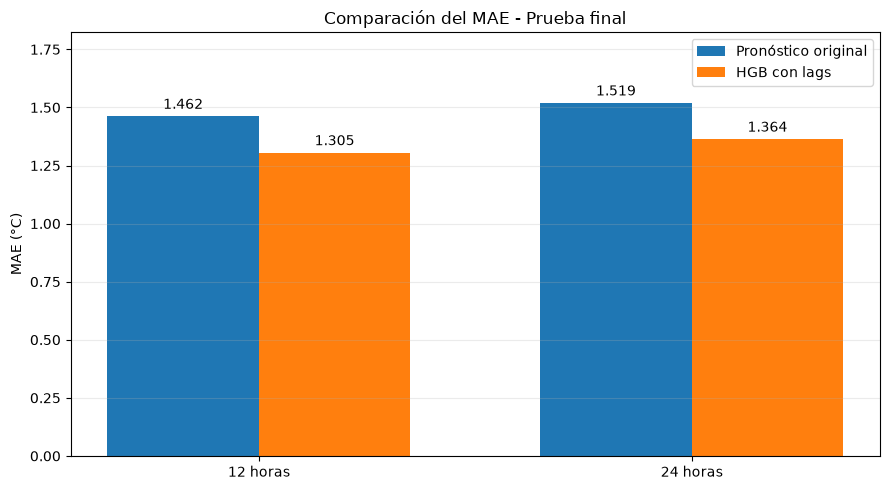

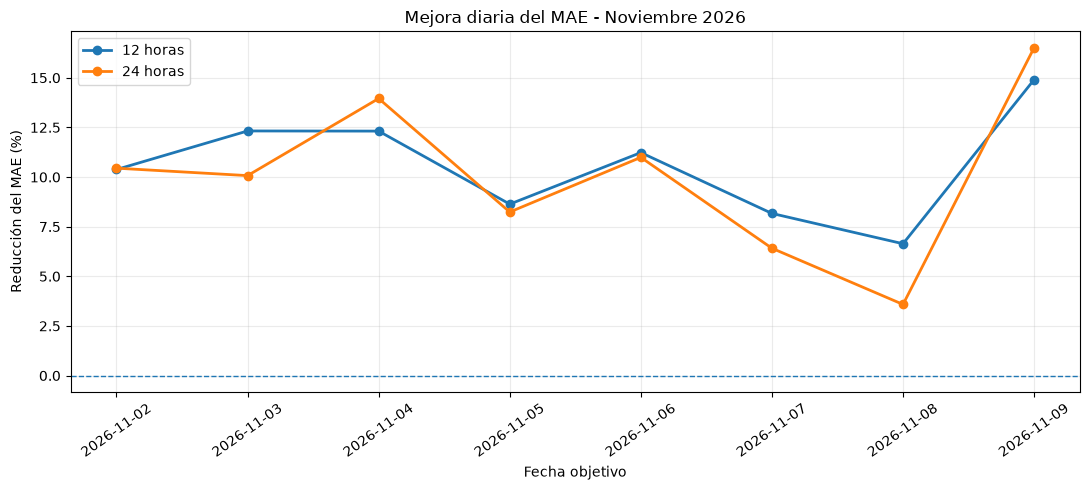

ARCHIVOS GENERADOS:
01_metricas_por_horizonte.csv - 423 bytes
02_metricas_globales.csv - 270 bytes
03_metricas_diarias.csv - 1342 bytes
04_mae_por_horizonte.png - 43582 bytes
05_mejora_diaria.png - 121792 bytes

CONTROL FINAL:
Resultados guardados correctamente.
No se modificó ni reentrenó el modelo.
No se calcularon nuevas predicciones.


In [28]:

# ==========================================
# 27. EXPORTAR RESULTADOS FINALES DEL TP3
# ==========================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------
# 1. CARPETA DE RESULTADOS
# ------------------------------------------

# El notebook se encuentra en TP3/notebooks/
# Guardamos los resultados en TP3/resultados_ml/

carpeta_resultados = (
    Path.cwd().parent / "resultados_ml"
)

carpeta_resultados.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------
# 2. GUARDAR LAS TRES TABLAS
# ------------------------------------------

df_resultados_test.to_csv(
    carpeta_resultados / "01_metricas_por_horizonte.csv",
    index=False,
    encoding="utf-8-sig"
)

df_resultado_global_test.to_csv(
    carpeta_resultados / "02_metricas_globales.csv",
    index=False,
    encoding="utf-8-sig"
)

df_test_diario.to_csv(
    carpeta_resultados / "03_metricas_diarias.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------
# 3. GRÁFICO DE MAE POR HORIZONTE
# ------------------------------------------

datos = df_resultados_test.sort_values(
    "horizonte_h"
)

x = np.arange(len(datos))
ancho = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

barras_original = ax.bar(
    x - ancho / 2,
    datos["MAE_original_c"],
    ancho,
    label="Pronóstico original"
)

barras_corregido = ax.bar(
    x + ancho / 2,
    datos["MAE_corregido_c"],
    ancho,
    label="HGB con lags"
)

ax.set_xticks(x)
ax.set_xticklabels(
    [f"{h} horas" for h in datos["horizonte_h"]]
)

ax.set_ylabel("MAE (°C)")
ax.set_title(
    "Comparación del MAE - Prueba final"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)

ax.bar_label(
    barras_original,
    fmt="%.3f",
    padding=3
)

ax.bar_label(
    barras_corregido,
    fmt="%.3f",
    padding=3
)

ax.set_ylim(
    0,
    datos["MAE_original_c"].max() * 1.2
)

fig.tight_layout()

fig.savefig(
    carpeta_resultados / "04_mae_por_horizonte.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------
# 4. GRÁFICO DE MEJORA DIARIA
# ------------------------------------------

tabla_grafico = df_test_diario.pivot(
    index="fecha",
    columns="horizonte_h",
    values="mejora_MAE_pct"
).sort_index()

fig, ax = plt.subplots(figsize=(11, 5))

for horizonte in [12, 24]:

    ax.plot(
        tabla_grafico.index,
        tabla_grafico[horizonte],
        marker="o",
        linewidth=2,
        label=f"{horizonte} horas"
    )

ax.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Mejora diaria del MAE - Noviembre 2026"
)

ax.set_ylabel("Reducción del MAE (%)")
ax.set_xlabel("Fecha objetivo")
ax.tick_params(axis="x", rotation=35)

ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()

fig.savefig(
    carpeta_resultados / "05_mejora_diaria.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------
# 5. COMPROBAR ARCHIVOS GENERADOS
# ------------------------------------------

archivos_generados = sorted(
    carpeta_resultados.iterdir()
)

print("ARCHIVOS GENERADOS:")

for archivo in archivos_generados:
    if archivo.is_file():
        print(
            archivo.name,
            "-",
            archivo.stat().st_size,
            "bytes"
        )

print("\nCONTROL FINAL:")
print("Resultados guardados correctamente.")
print("No se modificó ni reentrenó el modelo.")
print("No se calcularon nuevas predicciones.")



## Resultados y conclusiones del modelo de Machine Learning

### Objetivo

El objetivo del experimento fue desarrollar un modelo
capaz de corregir los errores de temperatura de los
pronósticos meteorológicos para horizontes de 12 y
24 horas.

Se definió como variable objetivo el error con signo:

**Error = Temperatura observada - Temperatura pronosticada**

La temperatura corregida se calculó sumando al
pronóstico original el error estimado por el modelo.

### Modelos evaluados

Se compararon cinco alternativas:

1. Pronóstico meteorológico original.
2. Regresión Ridge básica.
3. Regresión Ridge con errores históricos.
4. HistGradientBoosting básico.
5. HistGradientBoosting con errores históricos.

El mejor desempeño durante la validación correspondió
a HistGradientBoosting con errores históricos.

### Evaluación final independiente

Luego de seleccionar los hiperparámetros utilizando
la validación temporal, se reentrenó el modelo con
834.392 registros históricos cuyas etiquetas estaban
disponibles antes del corte del 1 de noviembre de 2026.

La evaluación final utilizó 140.822 registros
correspondientes al período del 2 al 9 de noviembre.

Los resultados fueron:

| Horizonte | MAE original | MAE corregido | Mejora |
|-----------|-------------:|--------------:|-------:|
| 12 horas | 1,4620 °C | 1,3051 °C | 10,73 % |
| 24 horas | 1,5194 °C | 1,3635 °C | 10,26 % |
| Global | 1,4907 °C | 1,3343 °C | 10,49 % |

El RMSE global disminuyó de 1,8800 °C a 1,7012 °C.

El sesgo medio también se redujo, pasando de
+0,3386 °C a +0,1541 °C.

### Análisis temporal

El modelo mejoró el MAE del pronóstico original en
los ocho días evaluados y en ambos horizontes.

La reconstrucción de errores históricos se realizó
respetando la disponibilidad temporal estimada de
cada observación.

Las observaciones de noviembre solamente pudieron
utilizarse como antecedentes de pronósticos posteriores
una vez alcanzado su momento estimado de disponibilidad.

Por lo tanto, los resultados corresponden a una
evaluación secuencial con actualización de antecedentes,
manteniendo congelados los parámetros del modelo.

### Limitaciones

- La evaluación final comprende solamente ocho días.
- Los registros de una misma estación y fecha no son
  estadísticamente independientes.
- La disponibilidad de las observaciones se aproximó
  mediante la hora de recolección y un margen de dos horas.
- Los resultados no representan una validación de
  funcionamiento en producción en tiempo real.
- No se realizaron nuevos ajustes de hiperparámetros
  utilizando el conjunto de prueba final.

### Conclusión

En el período de evaluación, HistGradientBoosting con
errores históricos redujo un 10,49 % el error absoluto
medio de los pronósticos originales de temperatura.

Los resultados respaldan la utilidad del aprendizaje
automático como método de corrección de pronósticos
meteorológicos para los horizontes estudiados.

Para determinar su capacidad de generalización a otros
períodos y condiciones meteorológicas sería necesario
realizar evaluaciones adicionales.


In [29]:

# ==========================================
# 28. INVENTARIO FINAL DEL PROYECTO
# ==========================================

from pathlib import Path
import pandas as pd

# El notebook está en TP3/notebooks/
raiz_proyecto = Path.cwd().parent

print("RAÍZ DEL PROYECTO:")
print(raiz_proyecto)

print("\nCARPETAS PRINCIPALES:")

for elemento in sorted(raiz_proyecto.iterdir()):
    if elemento.is_dir():
        print("[CARPETA]", elemento.name)
    else:
        print("[ARCHIVO]", elemento.name)

# ------------------------------------------
# 1. NOTEBOOKS EXISTENTES
# ------------------------------------------

print("\nNOTEBOOKS DEL PROYECTO:")

notebooks = sorted(
    raiz_proyecto.rglob("*.ipynb")
)

for notebook in notebooks:
    print(
        notebook.relative_to(raiz_proyecto)
    )

print("Total de notebooks:", len(notebooks))

# ------------------------------------------
# 2. DATASETS
# ------------------------------------------

carpeta_dataset = raiz_proyecto / "dataset"

archivos_csv = sorted(
    carpeta_dataset.glob(
        "forecast_observation_*.csv"
    )
)

print("\nDATASETS:")
print("CSV meteorológicos:", len(archivos_csv))

if archivos_csv:
    print("Primero:", archivos_csv[0].name)
    print("Último:", archivos_csv[-1].name)

# ------------------------------------------
# 3. RESULTADOS GENERADOS
# ------------------------------------------

carpeta_resultados = (
    raiz_proyecto / "resultados_ml"
)

print("\nRESULTADOS EXPORTADOS:")

if carpeta_resultados.exists():
    for archivo in sorted(
        carpeta_resultados.iterdir()
    ):
        if archivo.is_file():
            print(archivo.name)
else:
    print("No se encontró resultados_ml.")

# ------------------------------------------
# 4. MODELOS GUARDADOS
# ------------------------------------------

print("\nMODELOS ENTRENADOS:")

modelos = sorted(
    raiz_proyecto.rglob("*.joblib")
)

for modelo in modelos:
    print(
        modelo.relative_to(raiz_proyecto)
    )

# ------------------------------------------
# 5. RESUMEN
# ------------------------------------------

print("\nRESUMEN DEL PROYECTO:")

display(
    pd.DataFrame([{
        "notebooks": len(notebooks),
        "csv_meteorologicos": len(archivos_csv),
        "archivos_resultados": (
            len(list(carpeta_resultados.iterdir()))
            if carpeta_resultados.exists()
            else 0
        ),
        "modelos_guardados": len(modelos)
    }])
)

print("\nCONTROL FINAL:")
print("Inventario realizado en modo lectura.")
print("No se modificaron archivos ni modelos.")


RAÍZ DEL PROYECTO:
c:\Users\Jorge\Desktop\Jorge\Taller de Analisis de Datos I\TP3

CARPETAS PRINCIPALES:
[ARCHIVO] 00_auditoria_datos.ipynb
[ARCHIVO] 02_analisis_merge_tp2.ipynb
[ARCHIVO] 02_casteo_merge__tp2.ipynb
[ARCHIVO] 03_preparacion_modelado_tp3.ipynb
[ARCHIVO] Consigna TP3.pdf
[ARCHIVO] dashboard_tp3.py
[CARPETA] dataset
[CARPETA] dataset_backup
[CARPETA] notebooks
[CARPETA] resultados
[CARPETA] resultados_baselines
[CARPETA] resultados_ml
[CARPETA] resultados_tp3
[CARPETA] TP2 repaso

NOTEBOOKS DEL PROYECTO:
00_auditoria_datos.ipynb
02_analisis_merge_tp2.ipynb
02_casteo_merge__tp2.ipynb
03_preparacion_modelado_tp3.ipynb
notebooks\00_auditoria_y_consolidacion.ipynb
notebooks\01_analisis_estaciones.ipynb
notebooks\02_relaciones_bivariadas.ipynb
notebooks\03_analisis_temporal_solar.ipynb
notebooks\04_preparacion_datos_modelado.ipynb
notebooks\05_modelos_baseline.ipynb
notebooks\06_modelos_machine_learning.ipynb
TP2 repaso\analisis_merge_tp2_30dias.ipynb
TP2 repaso\analisisTP2Prop

,notebooks,csv_meteorologicos,archivos_resultados,modelos_guardados
0,13,61,5,1



CONTROL FINAL:
Inventario realizado en modo lectura.
No se modificaron archivos ni modelos.


In [30]:

# ==========================================
# 04 - CELDA 29
# EXPORTACIÓN PARA NOTEBOOK 06
# ==========================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

# 1. Verificar variables
assert "df_features_ml" in globals()
assert "variables_modelo_lags" in globals()

assert len(df_features_ml) == 854009
assert len(variables_modelo_lags) == 23

# 2. Asegurar variable objetivo
if "error_c" not in df_features_ml.columns:
    df_features_ml["error_c"] = (
        df_features_ml["temperature_observed_c"]
        - df_features_ml["temperature_forecast_c"]
    )

# 3. Seleccionar solamente datos históricos
columnas_control = [
    "station_id",
    "target_time_utc",
    "collection_time_utc",
    "forecast_generated_at_utc",
    "observation_collection_hour_utc",
    "error_c"
]

columnas_exportar = list(dict.fromkeys(
    columnas_control + list(variables_modelo_lags)
))

faltantes = set(columnas_exportar) - set(
    df_features_ml.columns
)

assert not faltantes, f"Columnas faltantes: {faltantes}"

df_exportacion = df_features_ml[
    columnas_exportar
].copy()

assert len(df_exportacion) == 854009
assert np.isfinite(df_exportacion["error_c"]).all()

fechas_objetivo = pd.to_datetime(
    df_exportacion["target_time_utc"],
    utc=True
)

assert (
    fechas_objetivo
    < pd.Timestamp("2026-11-02", tz="UTC")
).all(), "Se detectaron datos del test final."

# 4. Crear carpeta de intercambio
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

carpeta_salida = raiz / "datos_modelado"
carpeta_salida.mkdir(
    parents=True,
    exist_ok=True
)

# 5. Guardar dataset histórico
ruta_datos = (
    carpeta_salida / "features_historicas_tp3.pkl.gz"
)

df_exportacion.to_pickle(
    ruta_datos,
    compression="gzip",
    protocol=4
)

# 6. Guardar listado ordenado de predictores
ruta_variables = (
    carpeta_salida / "variables_modelo_lags.json"
)

ruta_variables.write_text(
    json.dumps(
        list(variables_modelo_lags),
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

# 7. Comprobar exportación
df_verificacion = pd.read_pickle(
    ruta_datos,
    compression="gzip"
)

assert df_verificacion.shape == df_exportacion.shape
assert df_verificacion.columns.tolist() == columnas_exportar

print("EXPORTACIÓN COMPLETADA")
print("Registros:", len(df_verificacion))
print("Predictores:", len(variables_modelo_lags))
print("Columnas exportadas:", len(columnas_exportar))

print("\nARCHIVOS:")
print(ruta_datos)
print(ruta_variables)

print("\nCONTROL FINAL:")
print("Solo datos históricos exportados.")
print("Noviembre 02-09 excluido.")
print("No se entrenaron modelos.")
print("No se modificó el modelo final.")


EXPORTACIÓN COMPLETADA
Registros: 854009
Predictores: 23
Columnas exportadas: 29

ARCHIVOS:
c:\Users\Jorge\Desktop\Jorge\Taller de Analisis de Datos I\TP3\datos_modelado\features_historicas_tp3.pkl.gz
c:\Users\Jorge\Desktop\Jorge\Taller de Analisis de Datos I\TP3\datos_modelado\variables_modelo_lags.json

CONTROL FINAL:
Solo datos históricos exportados.
Noviembre 02-09 excluido.
No se entrenaron modelos.
No se modificó el modelo final.
